<div style="border-left:4px solid #3D6FB0;padding:6px 0 8px 16px;"><div style="opacity:.72;font-size:12px;letter-spacing:1.4px;">Datos Masivos II · PRÁCTICA 4</div><div style="color:#3D6FB0;font-size:27px;font-weight:700;margin-top:4px;">BindingDB: análisis exploratorio de datos</div><div style="opacity:.72;font-size:14px;margin-top:6px;margin-bottom:10px;">Equipo Tres: Castrillo Cruz Karen Arlet, Ramos González Nadia, Zamora Antiga Ángel Javier.</div><img src="https://mmss.iimas.unam.mx/dmmss/wp-content/uploads/2026/02/cropped-LogoUNAM_IIMAS_Negro50-scaled-2.png" width="200"/></div>

## Instrucciones
Toma los datasets y crea un sistema de recomendación para cada uno. Aquí se trabajará con DB de afinidad de unión entre proteína objetivo consideradas fármacos candidatos y moléculas pequeñas (ligando). El valor que mas les sirve es `IC50` como "rating"

# <div style="border-left:4px solid #3D6FB0;padding:4px 0 6px 14px;margin:16px 0 6px 0;"><span style="color:#3D6FB0;font-size:21px;font-weight:700;">0. Contexto. Qué es BindingDB</span></div>

BindingDB es una base de datos pública de afinidades de unión medidas experimentalmente entre proteínas (consideradas *targets* farmacológicos) y moléculas pequeñas con características de fármaco (*ligandos*)$^{[3][4]}$.

**Origen de los datos.** Según la propia página $^{[3]}$, los datos provienen de:
- artículos científicos y patentes extraídos por los curadores del proyecto BindingDB;
- BioAssays confirmatorios de PubChem seleccionados;
- entradas de ChEMBL que tienen un target proteico bien definido (`TARGET_TYPE='PROTEIN'`).

El artículo de 2024 $^{[4]}$ explica que cerca de la mitad de las mediciones las extrajo el equipo de BindingDB de patentes de EE. UU. y artículos, y que la mayor parte del resto se importa de ChEMBL. El crecimiento reciente se debe sobre todo a las patentes.

**Técnicas experimentales.** Inhibición y cinética enzimática, calorimetría de titulación isotérmica (ITC), RMN y ensayos de radioligando o de competencia $^{[3]}$.

**Versión usada aquí.** Archivo `BindingDB_All_202611_tsv.zip`, actualizado el 2026-10-31 $^{[1]}$. La página de descarga reporta para "All data" **3,241,782 mediciones, 1,440,011 compuestos y 11,509 targets** $^{[1]}$. En la sección 3 se comprueba si el archivo coincide.

**Formato TSV.** BindingDB pasó de CSV a TSV porque algunos campos contienen comas legítimas, mientras que ningún campo contiene tabuladores $^{[2]}$. **Cada fila es una medición**: un ligando contra un target, con su valor de afinidad $^{[2]}$. Las celdas sin información quedan vacías $^{[2]}$.

**Licencia y cita** $^{[3]}$. Los datos curados por BindingDB se publican bajo CC BY 3.0, y los importados de ChEMBL bajo CC BY-SA 3.0. La referencia más reciente es Liu *et al.*, *Nucleic Acids Research* 53:D1633–D1644 (2025) $^{[4]}$.

## <div style="border-left:4px solid #3D6FB0;padding:4px 0 6px 14px;margin:16px 0 6px 0;"><span style="color:#3D6FB0;font-size:21px;font-weight:700;">0.1 Los Datos </span></div>

El encabezado tiene **640 columnas**, pero no todas contienen datos:

- **40 columnas fijas**: identidad del ligando, del target, la medición, la fuente y los identificadores externos.
- Un **bloque de 12 columnas que se repite por cada cadena proteica** del target. El encabezado prevé hasta 50 cadenas (40 + 12×50 = 640).

La especificación aclara que *"el número total de columnas puede variar de fila a fila"*, porque el bloque por cadena aparece tantas veces como cadenas tenga el target [2]. Un monómero ocupa un bloque y un trímero tres.

---

### Identidad del ligando (la molécula pequeña)

| Columna | Qué es | Formato / estructura que representa |
|---|---|---|
| `BindingDB Reactant_set_id` | ID interno **estable** de la "reacción de unión", es decir, de esta medición [2]. | Entero. Es la llave de cada fila y se mapea a *Entry ID + Assay ID* con un archivo aparte [1]. |
| `Ligand SMILES` | Estructura del ligando como cadena SMILES [2]. | Representa el **grafo molecular 2D**: nodos = átomos, aristas = enlaces [12]. Los átomos se escriben por su símbolo; los que no son del "subconjunto orgánico" van entre corchetes (`[Na+]`, `[nH]`). Las **minúsculas** indican átomos aromáticos. `=` y `#` son enlaces doble y triple. Los paréntesis marcan ramificaciones y los **dígitos** cierran anillos. `@`/`@@` indican quiralidad tetraédrica y `/` `\` la geometría de dobles enlaces. El **punto `.`** separa componentes desconectados, como sales o mezclas [12]. Una misma molécula admite muchos SMILES válidos, así que el SMILES **no es por sí mismo un identificador único**. |
| `Ligand InChI` | Identificador químico internacional de la IUPAC [13][14]. | Texto **por capas**: fórmula, conectividad, hidrógenos, carga, estereoquímica e isótopos. El prefijo `InChI=1S/` indica un InChI **estándar** versión 1 [13][14]. A diferencia del SMILES, es único por diseño para una estructura dada. |
| `Ligand InChI Key` | Hash de longitud fija del InChI [13][14]. | 27 caracteres con forma `AAAAAAAAAAAAAA-BBBBBBBBFV-P` [13][14]: **14 letras de conectividad (el "esqueleto")**, 8 letras que codifican el resto de capas (estereo, isótopos), `F` = `S` estándar / `N` no estándar, `V` = versión (`A` = 1), y `P` = protonación (`N` = neutro). No es reversible, y aunque hay colisiones posibles son rarísimas [14]. **Es el mejor identificador de molécula del archivo.** |
| `BindingDB MonomerID` | ID interno de BindingDB para el ligando [2]. | Entero. |
| `BindingDB Ligand Name` | Nombre asignado por quien curó el dato [2]. | Texto. *Observado en el archivo:* varios sinónimos separados por `::` (se verifica en la sección 7). |

---

### Identidad del target (la proteína)

| Columna | Qué es | Formato / estructura |
|---|---|---|
| `Target Name` | Nombre estándar de UniProt **más anotaciones de BindingDB** que indican construcciones truncadas o mutadas [2]. | Por ejemplo, `[262-930, L692P]` significa que la proteína usada abarca los residuos 262–930 y que la Leu 692 se cambió por Pro [2]. **Un mismo gen/proteína puede aparecer con varios nombres** según la construcción usada. |
| `Target Source Organism…` | Organismo de la proteína, según el curador o la fuente [2]. | Texto, nombre científico. |
| `Number of Protein Chains in Target` | Número de cadenas del target; **N > 1 indica un complejo multicadena** [2]. | Entero. Representa la **estructura cuaternaria**: un target puede ser un complejo de varias subunidades. |

**Bloque por cadena `i` (i = 1…N)** [2]:

| Columna | Qué es | Formato / estructura |
|---|---|---|
| `BindingDB Target Chain Sequence i` | Secuencia de aminoácidos de la cadena *i*. | **Estructura primaria** de la proteína, en código de **una letra por aminoácido** (A, C, D, … Y; X = cualquier residuo; U = selenocisteína; O = pirrolisina) [17]. |
| `PDB ID(s) of Target Chain i` | Entradas del PDB con esa cadena. | Criterio de coincidencia: **85 % de identidad de secuencia** [2]. Los IDs de entrada del PDB tienen 4 caracteres. |
| `UniProt (SwissProt) Recommended Name…` | Nombre recomendado en UniProtKB/Swiss-Prot. | Para que haya coincidencia con UniProt se exige **100 % de identidad** de secuencia y el **mismo organismo**, aunque no necesariamente la longitud completa [2]. |
| `UniProt (SwissProt) Entry Name…` | *Entry name* de Swiss-Prot. | Forma `X_Y`: X es un código mnemónico de la proteína (≤5 caracteres) e Y el código de especie (≤5, p. ej. `HUMAN`, `MOUSE`) [15]. **No es estable**; para citar se usa la *accession* [15]. |
| `UniProt (SwissProt) Primary ID…` | **Accession primaria**: el identificador estable y citable de la entrada [15][16]. | 6 o 10 caracteres alfanuméricos (p. ej. `P00533`, `A0A022YWF9`) [16]. |
| `…Secondary ID(s)…` | Accessions **obsoletas o deprecadas**, que se conservan por compatibilidad [2]. | Lista de texto. |
| `…Alternative ID(s)…` | IDs primarios o secundarios de cadenas con 100 % de coincidencia pero anotadas en **otro organismo** [2]. | Lista de texto. |
| `UniProt (TrEMBL) …` (5 columnas) | Equivalentes en **TrEMBL**, la sección **no revisada** (anotación automática) de UniProtKB. Swiss-Prot es la sección **revisada manualmente** [16]. | Mismos formatos. En TrEMBL, la X del *entry name* es la propia accession [15]. |

---

### Afinidad y cinética

Todas las afinidades están en **nM**, son reales > 0 y *"ocasionalmente se reportan como '>X'… siguiendo el formato de la fuente"* [2]. En todas, **un número menor significa una unión más fuerte** (se necesita menos compuesto).

| Columna | Qué mide | Interpretación |
|---|---|---|
| `Ki (nM)` | **Constante de inhibición**: constante de disociación en equilibrio del complejo proteína–inhibidor [7]. | Propiedad *intrínseca* del par y, en principio, independiente del ensayo. Suele **calcularse a partir de un IC50** con la ecuación de Cheng–Prusoff [5][7]. |
| `IC50 (nM)` | Concentración que **inhibe al 50 %** una actividad o la unión de un ligando de referencia [6][7]. | **Depende de las condiciones del ensayo**, como la concentración de sustrato o de radioligando. Por Cheng–Prusoff, `Ki = IC50 / (1 + [S]/Km)` en enzimas, o `Ki = IC50 / (1 + [L]/Kd)` en unión de radioligando [5][6][7]. Por eso, para inhibición competitiva, **IC50 ≥ Ki**. |
| `Kd (nM)` | **Constante de disociación en equilibrio**: `Kd = [R][L]/[RL]` [8]. | Concentración de ligando a la que la mitad de los sitios están ocupados [7]. Se relaciona con la cinética: `Kd = koff/kon` [8]. |
| `EC50 (nM)` | Concentración que produce el **50 % del efecto máximo** [7]. | Es una medida **funcional** (de respuesta), no de unión directa, y depende del sistema [7]. |
| `kon (M-1-s-1)` | **Constante de asociación** (velocidad de formación del complejo) [8][9]. | Unidades M⁻¹·s⁻¹. |
| `koff (s-1)` | **Constante de disociación cinética** [8][9]. | Unidades s⁻¹. **Tiempo de residencia** = 1/koff [9]. Dos compuestos con la misma Kd pueden tener cinéticas muy distintas [9]. |

**Escala logarítmica (p).** Es habitual expresar la afinidad como `pX = −log10(X en molar) = 9 − log10(X en nM)`: 1 nM equivale a p = 9 y 1 µM a p = 6 [10]. Así los valores, que abarcan muchos órdenes de magnitud, quedan en una escala lineal donde **mayor = más potente**. ChEMBL calcula su `pChEMBL` igual, **solo con relación "="**; los valores con `>`/`<` (censurados) quedan fuera [10].

**Calificadores `>` y `<`.** Indican que el valor real está **fuera del rango probado**. Por ejemplo, `>10000` normalmente significa que el compuesto no alcanzó el 50 % a la concentración máxima ensayada. Son **datos censurados**: dicen *"al menos/como mucho"*, no un valor puntual [2][10].

**Comparabilidad.** Mezclar IC50 de laboratorios distintos añade ruido. Kalliokoski *et al.* estimaron, con datos de ChEMBL, que la dispersión de IC50 públicos es ~25 % mayor que la de Ki, y que un factor ~2 entre Ki e IC50 es razonable [11]. Además, las condiciones del ensayo suelen faltar en las bases públicas [11].

---

### Condiciones y procedencia

| Columna | Qué es | Formato |
|---|---|---|
| `pH`, `Temp (C)` | Condiciones del ensayo [2]. | Real. *Observado:* la temperatura viene como texto `"37.00 C"`. |
| `Curation/DataSource` | Fuente u origen del dato [2]. | Típicamente BindingDB (literatura), ChEMBL, PubChem, PDSP Ki, CSAR, patentes US/WIPO o depositado por autores [2][3]. **PDSP Ki** es la base de Ki del *Psychoactive Drug Screening Program* del NIMH (receptores, transportadores, canales) [26]. **CSAR** es un recurso de datos de alta calidad para validar *docking* y *scoring* [27]. |
| `Article DOI` / `PMID` | Identificadores del artículo fuente (DOI y PubMed) [2]. | Texto / entero. |
| `BindingDB Entry DOI` | DOI de la **entrada de BindingDB** que agrupa estos datos [2]. | Texto. |
| `PubChem AID` | ID del **BioAssay** de PubChem del que viene el dato [2][19]. | Texto (`aid…`). |
| `Patent Number` | Número de patente, si aplica [2]. | Texto (`US…`, `WO…`). |
| `Authors`, `Institution` | Autores y lugar donde se midió (universidad o empresa) [2]. | Texto; los autores van separados por `;`. |
| `Date of publication`, `Date in BindingDB` | Fecha de publicación del artículo o patente, y fecha de curación o ingreso [2]. | Texto `M/D/AAAA`. |
| `Link to …` (3 columnas) | URLs preformateadas a BindingDB [2]. | Texto. |

---

### Identificadores externos del ligando

| Columna | Base de datos | Qué identifica / formato |
|---|---|---|
| `PubChem CID` | PubChem Compound | **Estructura química única** (estandarizada). Los estereoisómeros tienen CID distintos [19]. |
| `PubChem SID` | PubChem Substance | **Registro de un depositante**. Una misma estructura puede tener muchos SID, que se estandarizan a un CID [19]. CID, SID y AID son espacios numéricos distintos [19]. |
| `ChEBI ID of Ligand` | ChEBI (EBI) | Ontología de *Chemical Entities of Biological Interest*, curada manualmente y clasificada por clase química y rol biológico [21]. |
| `ChEMBL ID of Ligand` | ChEMBL | `CHEMBL` + entero (p. ej. `CHEMBL25` = aspirina). Nunca se reasigna [20]. |
| `DrugBank ID of Ligand` | DrugBank | `DB` + 5 dígitos [22]. Indica que el ligando es un **fármaco** aprobado o en investigación. |
| `IUPHAR_GRAC ID of Ligand` | IUPHAR/BPS Guide to PHARMACOLOGY | Ligand ID de GtoPdb, una base curada por expertos de interacciones fármaco–target [25]. |
| `KEGG ID of Ligand` | KEGG | `C` + 5 dígitos (KEGG COMPOUND) o `D` + 5 dígitos (KEGG DRUG) [23]. |
| `ZINC ID of Ligand` | ZINC | Base de compuestos **comprables** para cribado virtual [24]. |
| `Ligand HET ID in PDB` | wwPDB Chemical Component Dictionary | Código del componente químico en el PDB: históricamente **≤3 caracteres alfanuméricos** [18]. Como los códigos de 3 caracteres se agotaron, el wwPDB emite desde 2023 códigos de **5 caracteres**; los de 4 se omiten para no confundirlos con IDs de entrada del PDB [28]. |
| `PDB ID(s) for Ligand-Target Complex` | Protein Data Bank | **Estructuras 3D experimentales** del complejo, con criterio de proteína al 85 % de identidad [2]. |

## <div style="border-left:4px solid #3D6FB0;padding:4px 0 6px 14px;margin:16px 0 6px 0;"><span style="color:#3D6FB0;font-size:21px;font-weight:700;">0.2 Preparación de Entorno  </span></div>

El TSV descomprimido pesa **~9 GB** y no cabe cómodamente en RAM con 640 columnas de texto. La estrategia es:

1. Leer por **bloques** (*chunks*) solo las columnas útiles. Se usa `quoting=QUOTE_NONE`, porque SMILES y nombres pueden contener comillas y el TSV no usa comillas como delimitador [2].
2. En cada bloque, **convertir texto a tipos compactos** (números, fechas, banderas) y **resumir al vuelo** lo pesado: las secuencias de proteína se reemplazan por un ID y las URLs solo se cuentan.
3. Contar los nulos de *todas* las columnas leídas y guardar un **caché Parquet**, para que las siguientes ejecuciones tarden segundos.

> La primera ejecución recorre el archivo completo y tarda varios minutos. Para regenerar el caché basta con borrar `data/processed/`.

In [1]:
from pathlib import Path
import csv, re, json, time, warnings
from collections import Counter

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as mticker
from matplotlib.colors import LinearSegmentedColormap
from cycler import cycler

warnings.filterwarnings("ignore", category=FutureWarning)
pd.set_option("display.max_columns", 50)
pd.set_option("display.width", 180)
pd.set_option("display.max_colwidth", 80)

# ----------------------------- RUTAS -----------------------------
RAW_PATH  = Path("data/BindingDB_All_202611_tsv/BindingDB_All.tsv")
CACHE_DIR = Path("data/processed"); CACHE_DIR.mkdir(parents=True, exist_ok=True)
CACHE     = CACHE_DIR / "bindingdb_eda.parquet"
SEQ_CACHE = CACHE_DIR / "bindingdb_eda_secuencias.parquet"
META_JSON = CACHE_DIR / "bindingdb_eda_meta.json"
FIG_DIR   = Path("figs/eda"); FIG_DIR.mkdir(parents=True, exist_ok=True)
CHUNKSIZE = 200_000

# Conteos publicados en la página de descarga, release 202611 [1]
OFICIAL = {"mediciones": 3_241_782, "compuestos": 1_440_011, "targets": 11_509}

# ----------------------------- ESTILO -----------------------------
# Paleta categórica validada para daltonismo (orden fijo, no se cicla)
AZUL, NARANJA, AQUA, AMARILLO, MAGENTA, VERDE, VIOLETA, ROJO = (
    "#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4", "#008300", "#6250d6", "#e34948")
CAT = [AZUL, NARANJA, AQUA, AMARILLO, MAGENTA, VERDE, VIOLETA, ROJO]
GRIS = "#8a8984"
# Rampa secuencial de un solo tono (azul) para mapas de calor
SEQ_CMAP = LinearSegmentedColormap.from_list(
    "azul", ["#f4f8fd", "#cde2fb", "#9ec5f4", "#6da7ec", "#3987e5", "#256abf", "#184f95", "#0d366b"])

plt.rcParams.update({
    "figure.dpi": 110, "savefig.dpi": 130,
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.edgecolor": "#b5b4ae", "axes.linewidth": 0.8,
    "axes.grid": True, "grid.color": "#e6e5e0", "grid.linewidth": 0.6, "axes.axisbelow": True,
    "axes.labelcolor": "#52514e", "xtick.color": "#52514e", "ytick.color": "#52514e",
    "axes.titlesize": 11, "axes.titleweight": "bold", "axes.titlelocation": "left",
    "font.size": 9.5, "legend.frameon": False,
    "axes.prop_cycle": cycler(color=CAT),
})

def guardar(fig, nombre):
    fig.tight_layout()
    fig.savefig(FIG_DIR / f"{nombre}.png", bbox_inches="tight")
    plt.show()

def pct(a, b):
    return 100 * a / b if b else float("nan")

H = {}   # hallazgos clave que se van acumulando para el resumen final
print("Archivo crudo:", RAW_PATH, "| existe:", RAW_PATH.exists(),
      f"| {RAW_PATH.stat().st_size/1e9:.2f} GB" if RAW_PATH.exists() else "")

Archivo crudo: data\BindingDB_All_202611_tsv\BindingDB_All.tsv | existe: False 


# <div style="border-left:4px solid #3D6FB0;padding:4px 0 6px 14px;margin:16px 0 6px 0;"><span style="color:#3D6FB0;font-size:21px;font-weight:700;">1. Encabezado y resolución de nombres de columna</span></div>

Se lee solo el encabezado y se agrupan las columnas en *fijas* y *por cadena*. Los nombres se normalizan (espacios múltiples → uno) para que el código sea robusto entre versiones del archivo.

In [3]:
COLS = pd.read_csv(RAW_PATH, sep="\t", nrows=0, quoting=csv.QUOTE_NONE).columns.tolist()
NORM = {re.sub(r"\s+", " ", c).strip(): c for c in COLS}

def col(nombre):
    """Nombre real de la columna a partir del nombre normalizado."""
    return NORM[re.sub(r"\s+", " ", nombre).strip()]

N_CHAINS_COL = next(c for c in COLS if c.startswith("Number of Protein Chains"))
idx_chain = COLS.index(N_CHAINS_COL)
FIJAS = COLS[: idx_chain + 1]
POR_CADENA = COLS[idx_chain + 1:]
n_bloques = len(POR_CADENA) // 12

print(f"Columnas totales en el encabezado : {len(COLS)}")
print(f"Columnas fijas (incl. nº cadenas) : {len(FIJAS)}")
print(f"Columnas por cadena               : {len(POR_CADENA)} = 12 × {n_bloques} bloques")
print("\nBloque que se repite por cadena:")
for c in POR_CADENA[:12]:
    print("   ·", re.sub(r" 1$", " i", c))

C = {
    "rsid": "BindingDB Reactant_set_id", "smiles": "Ligand SMILES", "inchi": "Ligand InChI",
    "inchikey": "Ligand InChI Key", "monomer": "BindingDB MonomerID", "lig_name": "BindingDB Ligand Name",
    "target": "Target Name", "organism": "Target Source Organism According to Curator or DataSource",
    "Ki": "Ki (nM)", "IC50": "IC50 (nM)", "Kd": "Kd (nM)", "EC50": "EC50 (nM)",
    "kon": "kon (M-1-s-1)", "koff": "koff (s-1)", "pH": "pH", "temp": "Temp (C)",
    "source": "Curation/DataSource", "doi": "Article DOI", "entry_doi": "BindingDB Entry DOI",
    "pmid": "PMID", "aid": "PubChem AID", "patent": "Patent Number", "authors": "Authors",
    "pub_date": "Date of publication", "bdb_date": "Date in BindingDB", "institution": "Institution",
    "het": "Ligand HET ID in PDB", "pdb_complex": "PDB ID(s) for Ligand-Target Complex",
    "cid": "PubChem CID", "sid": "PubChem SID", "chebi": "ChEBI ID of Ligand", "chembl": "ChEMBL ID of Ligand",
    "drugbank": "DrugBank ID of Ligand", "iuphar": "IUPHAR_GRAC ID of Ligand", "kegg": "KEGG ID of Ligand",
    "zinc": "ZINC ID of Ligand",
}
C = {k: col(v) for k, v in C.items()}
C["n_chains"] = N_CHAINS_COL

SEQ   = {i: col(f"BindingDB Target Chain Sequence {i}") for i in range(1, n_bloques + 1)}
SP_ID = {i: col(f"UniProt (SwissProt) Primary ID of Target Chain {i}") for i in range(1, n_bloques + 1)}
CH1 = {
    "sp_name1":  col("UniProt (SwissProt) Recommended Name of Target Chain 1"),
    "sp_entry1": col("UniProt (SwissProt) Entry Name of Target Chain 1"),
    "trembl1":   col("UniProt (TrEMBL) Primary ID of Target Chain 1"),
    "pdb_chain1": col("PDB ID(s) of Target Chain 1"),
}
USECOLS = list(dict.fromkeys(FIJAS + list(SEQ.values()) + list(SP_ID.values()) + list(CH1.values())))
print(f"\nColumnas que se leerán: {len(USECOLS)} de {len(COLS)}")

Columnas totales en el encabezado : 640
Columnas fijas (incl. nº cadenas) : 40
Columnas por cadena               : 600 = 12 × 50 bloques

Bloque que se repite por cadena:
   · BindingDB Target Chain Sequence i
   · PDB ID(s) of Target Chain i
   · UniProt (SwissProt) Recommended Name of Target Chain i
   · UniProt (SwissProt) Entry Name of Target Chain i
   · UniProt (SwissProt) Primary ID of Target Chain i
   · UniProt (SwissProt) Secondary ID(s) of Target Chain i
   · UniProt (SwissProt) Alternative ID(s) of Target Chain i
   · UniProt (TrEMBL) Submitted Name of Target Chain i
   · UniProt (TrEMBL) Entry Name of Target Chain i
   · UniProt (TrEMBL) Primary ID of Target Chain i
   · UniProt (TrEMBL) Secondary ID(s) of Target Chain i
   · UniProt (TrEMBL) Alternative ID(s) of Target Chain i

Columnas que se leerán: 144 de 640


# <div style="border-left:4px solid #3D6FB0;padding:4px 0 6px 14px;margin:16px 0 6px 0;"><span style="color:#3D6FB0;font-size:21px;font-weight:700;">2. Procesamiento por bloques</span></div>

Decisiones de limpieza **mínimas y reversibles** (es EDA, no preprocesamiento):

- **Afinidades.** Se separa el calificador (`>`, `<`, `~`, `=`) del número. El valor se guarda como `float` y el calificador en otra columna. Los textos que no se pueden convertir se cuentan y se guardan ejemplos.
- **Fechas.** Formato `M/D/AAAA`. Los marcadores vacíos como `//` quedan como faltantes.
- **Temperatura.** `"37.00 C"` → `37.0`.
- **Secuencias.** Cada secuencia distinta recibe un ID entero y se guarda en una tabla aparte. Así no se repiten ~600 caracteres en 3 M de filas.
- **Complejos multicadena.** Se concatenan las accessions UniProt de todas sus cadenas.
- **Nulos.** Se cuentan por columna antes de cualquier transformación.

Con `keep_default_na=False` solo una celda **vacía** se trata como nula. Así un ligando o target llamado literalmente `"NA"` no se pierde.

In [4]:
AFF = ["Ki", "IC50", "Kd", "EC50", "kon", "koff"]
TIPOS = ["Ki", "IC50", "Kd", "EC50"]
ID_EXT = ["cid", "sid", "chebi", "chembl", "drugbank", "iuphar", "kegg", "zinc"]

def separar_calificador(s):
    s = s.str.strip()
    qual = s.str.extract(r"^([<>~=]+)", expand=False)
    num = pd.to_numeric(s.str.replace(r"^[<>~=]+\s*", "", regex=True), errors="coerce")
    no_parse = s.notna() & num.isna()
    return qual, num, no_parse, s[no_parse]

def a_str(s):
    return s.astype("string[pyarrow]")

SEQ_IDS = {}

def id_secuencia(s):
    for u in s.dropna().unique():
        if u not in SEQ_IDS:
            SEQ_IDS[u] = len(SEQ_IDS)
    return s.map(SEQ_IDS).astype("Int32")

def procesar_chunk(df, meta):
    o = pd.DataFrame(index=df.index)
    o["rsid"]       = pd.to_numeric(df[C["rsid"]], errors="coerce").astype("Int64")
    o["smiles"]     = a_str(df[C["smiles"]])
    o["inchi_std"]  = df[C["inchi"]].str.startswith("InChI=1S/").astype("boolean")
    o["inchikey"]   = a_str(df[C["inchikey"]].str.strip())
    o["monomer_id"] = pd.to_numeric(df[C["monomer"]], errors="coerce").astype("Int64")
    nombres = df[C["lig_name"]].str.split("::")
    o["lig_name"]   = a_str(nombres.str[0])
    o["lig_n_nombres"] = nombres.str.len().astype("Int16")
    o["target"]     = a_str(df[C["target"]])
    o["organism"]   = a_str(df[C["organism"]])
    for a in AFF:
        q, v, bad, ejemplos = separar_calificador(df[C[a]])
        o[a], o[f"{a}_qual"] = v, a_str(q)
        meta["no_parse"][a] = meta["no_parse"].get(a, 0) + int(bad.sum())
        meta["no_parse_ej"].setdefault(a, [])
        meta["no_parse_ej"][a] = (meta["no_parse_ej"][a] + ejemplos.head(5).tolist())[:15]
    o["pH"]         = pd.to_numeric(df[C["pH"]].str.strip(), errors="coerce")
    o["temp_raw_ok"] = df[C["temp"]].str.fullmatch(r"\s*-?[\d.]+\s*C\s*").astype("boolean")
    o["temp_C"]     = pd.to_numeric(df[C["temp"]].str.replace("C", "", regex=False).str.strip(), errors="coerce")
    o["source"]     = a_str(df[C["source"]])
    o["doi"]        = a_str(df[C["doi"]])
    o["entry_doi"]  = a_str(df[C["entry_doi"]])
    o["pmid"]       = pd.to_numeric(df[C["pmid"]], errors="coerce").astype("Int64")
    o["aid"]        = a_str(df[C["aid"]])
    o["patent"]     = a_str(df[C["patent"]])
    o["n_autores"]  = (df[C["authors"]].str.count(";") + 1).astype("Int16")
    o["pub_date"]   = pd.to_datetime(df[C["pub_date"]], format="%m/%d/%Y", errors="coerce")
    o["bdb_date"]   = pd.to_datetime(df[C["bdb_date"]], format="%m/%d/%Y", errors="coerce")
    o["institution"] = a_str(df[C["institution"]])
    o["het"]        = a_str(df[C["het"]].str.strip())
    o["pdb_complex"] = a_str(df[C["pdb_complex"]])
    for k in ID_EXT:
        o[f"id_{k}"] = a_str(df[C[k]].str.strip())
    # --- target / cadenas ---
    o["n_chains"]   = pd.to_numeric(df[C["n_chains"]], errors="coerce").astype("Int16")
    o["n_cadenas_con_secuencia"] = df[list(SEQ.values())].notna().sum(axis=1).astype("int16")
    o["seq_id1"]    = id_secuencia(df[SEQ[1]])
    o["uniprot1"]   = a_str(df[SP_ID[1]].str.strip())
    for k, c in CH1.items():
        o[k] = a_str(df[c])
    multi = o["n_cadenas_con_secuencia"] > 1
    o["uniprot_complejo"] = pd.Series(pd.NA, index=df.index, dtype="string[pyarrow]")
    if multi.any():
        sp = df.loc[multi, list(SP_ID.values())]
        o.loc[multi, "uniprot_complejo"] = sp.apply(lambda r: ",".join(sorted(r.dropna())), axis=1)
    return o

def construir_cache():
    meta = {"filas": 0, "nulos": {}, "no_parse": {}, "no_parse_ej": {}}
    nulos = pd.Series(0, index=USECOLS, dtype="int64")
    partes, t0 = [], time.time()
    lector = pd.read_csv(RAW_PATH, sep="\t", usecols=USECOLS, dtype=str, quoting=csv.QUOTE_NONE,
                         keep_default_na=False, na_values=[""], chunksize=CHUNKSIZE,
                         on_bad_lines="warn", encoding="utf-8", encoding_errors="replace")
    for i, df in enumerate(lector):
        meta["filas"] += len(df)
        nulos = nulos.add(df.isna().sum(), fill_value=0)
        partes.append(procesar_chunk(df, meta))
        print(f"  bloque {i+1:>3}: {meta['filas']:>10,} filas  ({time.time()-t0:,.0f} s)", end="\r")
    print()
    bd = pd.concat(partes, ignore_index=True); del partes
    for c in ["target", "organism", "source", "institution", "het", "entry_doi", "doi", "aid", "patent",
              "uniprot1", "sp_name1", "sp_entry1", "trembl1", "pdb_chain1", "uniprot_complejo",
              "id_kegg", "id_drugbank", "id_iuphar", "id_chebi"] + [f"{a}_qual" for a in AFF]:
        bd[c] = bd[c].astype("category")
    seqs = pd.DataFrame({"seq_id1": np.arange(len(SEQ_IDS), dtype="int32"), "secuencia": list(SEQ_IDS)})
    meta["nulos"] = {k: int(v) for k, v in nulos.items()}
    meta["segundos"] = round(time.time() - t0, 1)
    bd.to_parquet(CACHE, index=False); seqs.to_parquet(SEQ_CACHE, index=False)
    META_JSON.write_text(json.dumps(meta, ensure_ascii=False, indent=1))
    return bd, seqs, meta

if CACHE.exists() and SEQ_CACHE.exists() and META_JSON.exists():
    bd = pd.read_parquet(CACHE); seqs = pd.read_parquet(SEQ_CACHE)
    META = json.loads(META_JSON.read_text())
    print("Caché cargado.")
else:
    print("Construyendo caché (una sola vez)…")
    bd, seqs, META = construir_cache()
print(f"Filas: {len(bd):,} | columnas derivadas: {bd.shape[1]} | "
      f"RAM: {bd.memory_usage(deep=True).sum()/1e9:.2f} GB | lectura original: {META['segundos']:,.0f} s")

Construyendo caché (una sola vez)…
  bloque  17:  3,243,660 filas  (258 s)
Filas: 3,243,660 | columnas derivadas: 53 | RAM: 1.30 GB | lectura original: 261 s


# <div style="border-left:4px solid #3D6FB0;padding:4px 0 6px 14px;margin:16px 0 6px 0;"><span style="color:#3D6FB0;font-size:21px;font-weight:700;">3. Estructura general</span></div>

### Vista rápida y tipos

In [5]:
vista = ["rsid", "inchikey", "lig_name", "target", "organism", "Ki", "IC50", "IC50_qual", "Kd", "EC50",
         "pH", "temp_C", "source", "pub_date", "uniprot1", "n_chains"]
display(bd[vista].head(8))
tipos = bd.dtypes.map(lambda d: "category" if isinstance(d, pd.CategoricalDtype) else str(d))
display(tipos.value_counts().rename("nº columnas").to_frame())

,rsid,inchikey,lig_name,target,organism,Ki,IC50,IC50_qual,Kd,EC50,pH,temp_C,source,pub_date,uniprot1,n_chains
0,1,XGEGDSLAQZJGCW-UHFFFAOYSA-N,"6-[(4R,5S,6S,7R)-4,7-dibenzyl-3-(5-carboxypentyl)-5,6-dihydroxy-2-oxo-1,3-di...",Dimer of Gag-Pol polyprotein [501-599],Human immunodeficiency virus 1,0.24,NaN,<NA>,NaN,NaN,5.5,37.0,Curated from the literature by BindingDB,1996-08-30,P03367,1
1,2,UZLMEAPBHYEHAC-UHFFFAOYSA-N,"(4R,5S,6S,7R)-4,7-dibenzyl-5,6-dihydroxy-1,3-bis[(2E)-3-(1H-pyrazol-4-yl)pro...",Dimer of Gag-Pol polyprotein [501-599],Human immunodeficiency virus 1,0.25,NaN,<NA>,NaN,NaN,5.5,37.0,Curated from the literature by BindingDB,1996-08-30,P03367,1
2,3,HYNYUFZPPJMPOB-UHFFFAOYSA-N,"(4R,5S,6S,7R)-4,7-dibenzyl-1-(cyclopropylmethyl)-5,6-dihydroxy-3-[(2E)-3-(1H...",Dimer of Gag-Pol polyprotein [501-599],Human immunodeficiency virus 1,0.41,NaN,<NA>,NaN,NaN,5.5,37.0,Curated from the literature by BindingDB,1996-08-30,P03367,1
3,4,YXVAZXDWVZTGGD-UHFFFAOYSA-N,"(4R,5S,6S,7R)-4,7-dibenzyl-1-(cyclopropylmethyl)-5,6-dihydroxy-3-(6-hydroxyh...",Dimer of Gag-Pol polyprotein [501-599],Human immunodeficiency virus 1,0.80,NaN,<NA>,NaN,NaN,5.5,37.0,Curated from the literature by BindingDB,1996-08-30,P03367,1
4,5,WWTSWTPNILRSJX-UHFFFAOYSA-N,"(4R,5S,6S,7R)-4,7-dibenzyl-1-(cyclopropylmethyl)-5,6-dihydroxy-3-(5-hydroxyp...",Dimer of Gag-Pol polyprotein [501-599],Human immunodeficiency virus 1,0.99,NaN,<NA>,NaN,NaN,5.5,37.0,Curated from the literature by BindingDB,1996-08-30,P03367,1
5,6,QDUGHFLRTUTUJH-UHFFFAOYSA-N,"(4R,5S,6S,7R)-4,7-dibenzyl-1-butyl-3-(cyclopropylmethyl)-5,6-dihydroxy-1,3-d...",Dimer of Gag-Pol polyprotein [501-599],Human immunodeficiency virus 1,1.10,NaN,<NA>,NaN,NaN,5.5,37.0,Curated from the literature by BindingDB,1996-08-30,P03367,1
6,7,ACIVSSKFPCODPQ-UHFFFAOYSA-N,CHEMBL287355,Dimer of Gag-Pol polyprotein [501-599],Human immunodeficiency virus 1,1.30,NaN,<NA>,NaN,NaN,5.5,37.0,Curated from the literature by BindingDB,1996-08-30,P03367,1
7,8,IXMFJRZMSUIMQY-UHFFFAOYSA-N,"(4R,5S,6S,7R)-4,7-dibenzyl-5,6-dihydroxy-1,3-bis(5-hydroxypentyl)-1,3-diazep...",Dimer of Gag-Pol polyprotein [501-599],Human immunodeficiency virus 1,1.40,NaN,<NA>,NaN,NaN,5.5,37.0,Curated from the literature by BindingDB,1996-08-30,P03367,1


,nº columnas
category,25
float64,8
string,8
Int64,3
Int16,3
boolean,2
datetime64[ns],2
int16,1
Int32,1


### Verificación con el conteo oficial

La página reporta 3,241,782 mediciones, 1,440,011 compuestos y 11,509 targets [1]. Contamos de varias maneras porque **"compuesto" y "target" admiten más de una definición**:

- **Compuesto**: el `MonomerID` interno de BindingDB, la molécula exacta (`InChIKey`) o el esqueleto sin estereoquímica (primer bloque del InChIKey).
- **Target**: el `Target Name` (incluye construcciones y mutantes), la proteína canónica (`UniProt` de la cadena 1) o la secuencia exacta.

In [6]:
n = len(bd)
ik = bd["inchikey"].dropna()
conteos = pd.DataFrame([
    ("Mediciones", OFICIAL["mediciones"], "filas del TSV", n),
    ("Compuestos", OFICIAL["compuestos"], "MonomerID distintos", bd["monomer_id"].nunique()),
    ("Compuestos", OFICIAL["compuestos"], "InChIKey distintos", ik.nunique()),
    ("Compuestos", OFICIAL["compuestos"], "esqueletos (InChIKey[:14])", ik.str.slice(0, 14).nunique()),
    ("Compuestos", OFICIAL["compuestos"], "SMILES distintos (texto)", bd["smiles"].nunique()),
    ("Targets", OFICIAL["targets"], "Target Name distintos", bd["target"].nunique()),
    ("Targets", OFICIAL["targets"], "UniProt cadena 1 distintos", bd["uniprot1"].nunique()),
    ("Targets", OFICIAL["targets"], "secuencias cadena 1 distintas", bd["seq_id1"].nunique()),
], columns=["Concepto", "Página oficial [1]", "Definición usada aquí", "Este archivo"])
conteos["Diferencia %"] = (100 * (conteos["Este archivo"] / conteos["Página oficial [1]"] - 1)).round(2)
display(conteos.style.format({"Página oficial [1]": "{:,}", "Este archivo": "{:,}", "Diferencia %": "{:+.2f}"}))

print(f"Reactant_set_id único por fila: {bd['rsid'].is_unique}  (nulos: {bd['rsid'].isna().sum()})")
H["Mediciones (filas)"] = f"{n:,} (oficial {OFICIAL['mediciones']:,})"
H["Ligandos distintos (InChIKey)"] = f"{ik.nunique():,}"
H["Targets distintos (Target Name / UniProt)"] = f"{bd['target'].nunique():,} / {bd['uniprot1'].nunique():,}"

,Concepto,Página oficial [1],Definición usada aquí,Este archivo,Diferencia %
0,Mediciones,"3,241,782",filas del TSV,"3,243,660",+0.06
1,Compuestos,"1,440,011",MonomerID distintos,"1,445,784",+0.40
2,Compuestos,"1,440,011",InChIKey distintos,"1,354,629",-5.93
3,Compuestos,"1,440,011",esqueletos (InChIKey[:14]),"1,341,216",-6.86
4,Compuestos,"1,440,011",SMILES distintos (texto),"1,438,824",-0.08
5,Targets,"11,509",Target Name distintos,"8,940",-22.32
6,Targets,"11,509",UniProt cadena 1 distintos,"8,594",-25.33
7,Targets,"11,509",secuencias cadena 1 distintas,"11,018",-4.27


Reactant_set_id único por fila: True  (nulos: 0)


**Cómo leer la tabla.**

- **Mediciones.** El número de filas difiere del oficial en menos de 0.1 %, y el `Reactant_set_id` es único y no tiene nulos. El archivo se leyó completo. La pequeña diferencia es compatible con que la cifra de la página se calcule en un momento o con un criterio ligeramente distinto al de la generación del TSV.
- **Compuestos.** El conteo oficial coincide casi exactamente con los `MonomerID` distintos: BindingDB cuenta compuestos por su ID interno. El número de **esqueletos** es menor que el de InChIKey porque los estereoisómeros, tautómeros fijos o isótopos de una misma conectividad comparten los primeros 14 caracteres [13][14]. Los **SMILES** distintos pueden exceder a los InChIKey, porque una misma molécula admite varias escrituras SMILES [12].
- **Targets.** `Target Name` distingue **construcciones** (truncamientos, mutantes [2]), así que da más targets que UniProt. Aun así, ambos quedan por debajo de la cifra oficial. Lo que más se le acerca es el número de **secuencias distintas**. Esto sugiere que BindingDB cuenta como "target" cada polímero o secuencia proteica, y que la diferencia restante vendría de las cadenas 2…N de los complejos, que aquí no se cuentan como target. La página no documenta la definición exacta, así que es una **inferencia a partir de los datos**, no una afirmación de la fuente.

# <div style="border-left:4px solid #3D6FB0;padding:4px 0 6px 14px;margin:16px 0 6px 0;"><span style="color:#3D6FB0;font-size:21px;font-weight:700;">4. Valores faltantes</span></div>

La especificación dice que una celda vacía significa "información no disponible" [2]. Primero se miran las 40 columnas fijas y después los bloques por cadena.

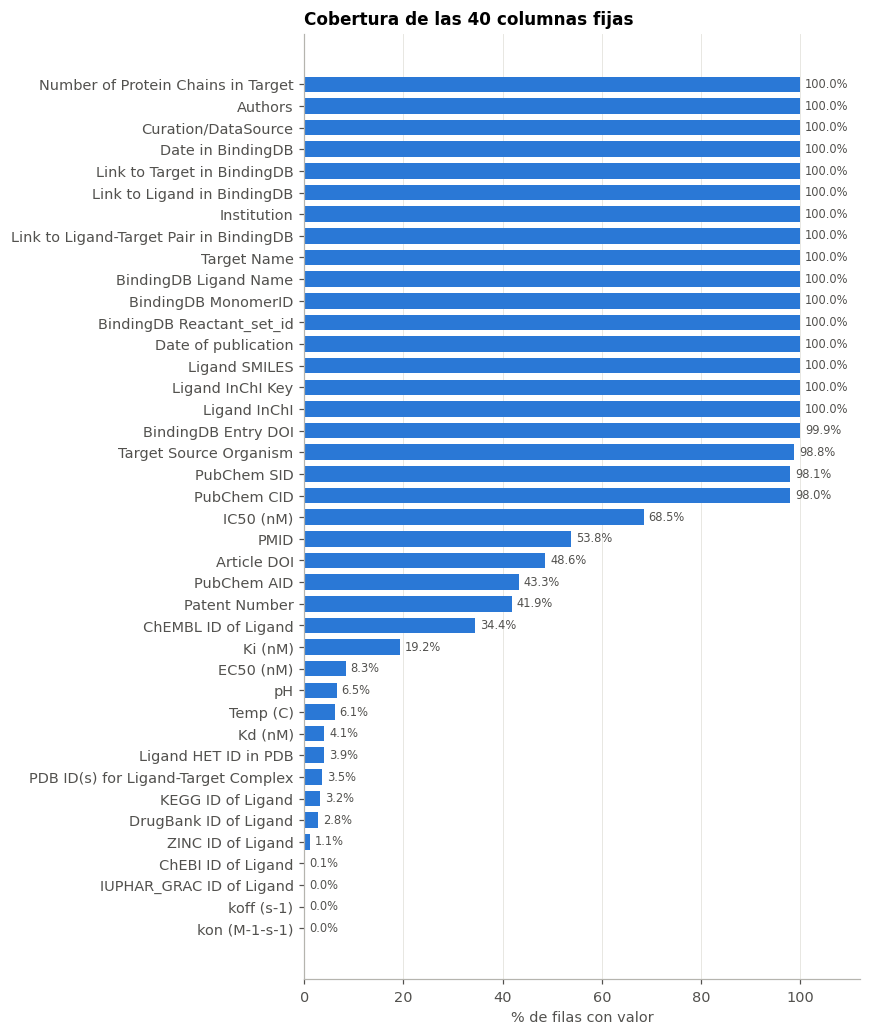

In [7]:
nulos = pd.Series(META["nulos"]); N = META["filas"]
pct_lleno = (100 * (1 - nulos[FIJAS] / N)).sort_values()
etiquetas = [re.sub(r" According to Curator or DataSource| \(>1 implies a multichain complex\)", "", c) for c in pct_lleno.index]

fig, ax = plt.subplots(figsize=(8, 9.5))
ax.barh(etiquetas, pct_lleno.values, color=AZUL, height=0.72)
for y, v in enumerate(pct_lleno.values):
    ax.text(v + 1, y, f"{v:.1f}%", va="center", fontsize=7.5, color="#52514e")
ax.set_xlim(0, 112); ax.set_xlabel("% de filas con valor"); ax.grid(axis="y", visible=False)
ax.set_title("Cobertura de las 40 columnas fijas")
guardar(fig, "04_cobertura_columnas_fijas")

Última cadena con alguna secuencia: 50 de 50 bloques previstos
Columnas por cadena completamente vacías: 0 de 600 (≈ 0% del encabezado)


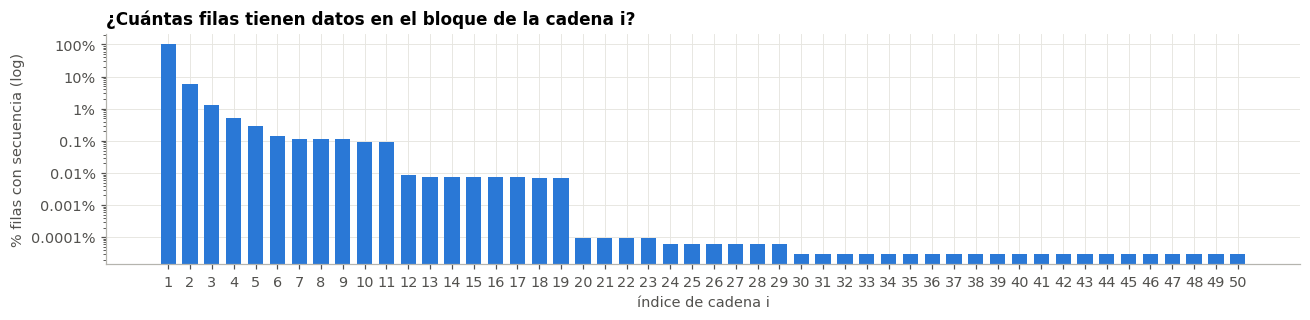

In [8]:
cob_cadena = pd.Series({i: 100 * (1 - nulos[SEQ[i]] / N) for i in SEQ})
ult = cob_cadena[cob_cadena > 0].index.max()
print(f"Última cadena con alguna secuencia: {ult} de {n_bloques} bloques previstos")
print(f"Columnas por cadena completamente vacías: {sum(nulos[SEQ[i]] == N for i in SEQ) * 12} "
      f"de {len(POR_CADENA)} (≈ {pct(sum(nulos[SEQ[i]] == N for i in SEQ) * 12, len(COLS)):.0f}% del encabezado)")

fig, ax = plt.subplots(figsize=(12, 3))
mostrar = cob_cadena.loc[1:max(ult, 2)]
ax.bar(mostrar.index.astype(str), mostrar.values, color=AZUL, width=0.7)
ax.set_yscale("log"); ax.set_xlabel("índice de cadena i"); ax.set_ylabel("% filas con secuencia (log)")
ax.yaxis.set_major_formatter(mticker.FuncFormatter(lambda v, _: f"{v:g}%"))
ax.set_title("¿Cuántas filas tienen datos en el bloque de la cadena i?")
guardar(fig, "04_cobertura_bloques_cadena")

**Interpretación.**

- **Columnas casi siempre llenas**: identidad del ligando (SMILES, InChIKey, MonomerID), target, organismo, fuente y fechas. Son el "esqueleto" de cada medición.
- **Afinidades dispersas**: cada fila suele traer **un solo tipo** de medición (IC50, *o* Ki, *o* Kd…), así que esas columnas tienen muchos vacíos *por diseño*, no por mala calidad (se verifica en la sección 5).
- **Identificadores externos** (DrugBank, KEGG, IUPHAR, ChEBI, HET/PDB). Su cobertura baja es **informativa**: solo una minoría de los ligandos son fármacos conocidos o tienen estructura cristalográfica.
- **Bloques por cadena**: la cobertura cae en picada a partir de la cadena 2 (escala log en la gráfica). La mayoría de los targets son de una sola cadena y solo un puñado de complejos muy grandes llega a llenar los 50 bloques. Las ~600 columnas por cadena existen para cubrir esos pocos casos extremos.

# <div style="border-left:4px solid #3D6FB0;padding:4px 0 6px 14px;margin:16px 0 6px 0;"><span style="color:#3D6FB0;font-size:21px;font-weight:700;">5. Mediciones de afinidad</span></div>

### Medición por fila

In [9]:
presente = pd.DataFrame({a: bd[a].notna() | bd[f"{a}_qual"].notna() for a in AFF})
cob = pd.DataFrame({
    "filas con valor": presente.sum(),
    "% de filas": (100 * presente.mean()).round(2),
    "valores numéricos": bd[AFF].notna().sum(),
    "no convertibles": pd.Series(META["no_parse"]),
})
display(cob.style.format({"filas con valor": "{:,}", "valores numéricos": "{:,}", "no convertibles": "{:,}", "% de filas": "{:.2f}"}))
print("Ejemplos de textos no convertibles:", {k: v[:5] for k, v in META["no_parse_ej"].items() if v})

mask = sum(presente[t].astype(int) * (1 << i) for i, t in enumerate(TIPOS))
etq = {m: " + ".join(t for i, t in enumerate(TIPOS) if m >> i & 1) or "(ninguno de los 4)" for m in range(16)}
combos = mask.map(etq).value_counts()
combos = pd.DataFrame({"filas": combos, "%": (100 * combos / n).round(3)})
display(combos)
H["Tipo de afinidad más frecuente"] = f"{cob['filas con valor'][TIPOS].idxmax()} ({cob['% de filas'][TIPOS].max():.1f}% de filas)"

,filas con valor,% de filas,valores numéricos,no convertibles
Ki,"623,701",19.23,"623,701",0
IC50,"2,220,490",68.46,"2,220,490",0
Kd,"131,531",4.06,"131,531",0
EC50,"270,787",8.35,"270,787",0
kon,"1,003",0.03,"1,003",3
koff,"1,019",0.03,"1,019",3


Ejemplos de textos no convertibles: {'kon': ['NV,', 'NV,', 'NV,'], 'koff': ['NV,', 'NV,', 'NV,']}


,filas,%
IC50,2215710,68.309
Ki,619591,19.102
EC50,268416,8.275
Kd,131244,4.046
Ki + IC50,3070,0.095
(ninguno de los 4),2979,0.092
IC50 + EC50,1393,0.043
Ki + EC50,871,0.027
IC50 + Kd,209,0.006
Ki + IC50 + EC50,99,0.003


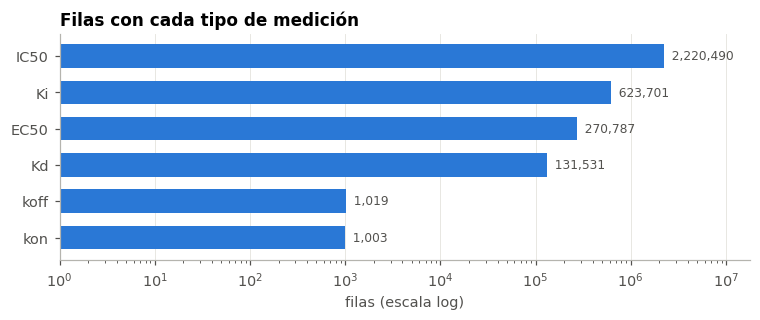

In [10]:
fig, ax = plt.subplots(figsize=(7, 3))
c4 = cob.loc[TIPOS + ["kon", "koff"], "filas con valor"].sort_values()
ax.barh(c4.index, c4.values, color=AZUL, height=0.65)
for y, v in enumerate(c4.values):
    ax.text(v, y, f"  {v:,}", va="center", fontsize=8, color="#52514e")
ax.set_xscale("log"); ax.set_xlim(1, c4.max() * 8); ax.set_xlabel("filas (escala log)"); ax.grid(axis="y", visible=False)
ax.set_title("Filas con cada tipo de medición")
guardar(fig, "05_tipos_medicion")

**Textos no convertibles.** En kon/koff aparece el texto `NV,`, que no es numérico y que la especificación no documenta [2]. Se trata como faltante.

**Interpretación.** Casi siempre hay **un tipo de medición por fila**. Una misma reacción de unión puede aparecer en filas distintas con Ki y con IC50, por ejemplo, pero rara vez en la misma fila. **IC50** domina por mucho: es el formato habitual de patentes y de química medicinal. **Ki** (frecuente en ensayos de radioligando, como en PDSP [26]) y **EC50** le siguen, y **Kd** es minoritario. Los datos **cinéticos** (kon/koff) son muy escasos.

### Valores censurados

Según la especificación, los valores a veces vienen como `">X"` [2]. Veamos cuántos y cuáles.

In [11]:
filas = []
for t in AFF:
    q = bd.loc[presente[t], f"{t}_qual"].astype("object").fillna("(sin calificador)")
    vc = q.value_counts()
    filas.append((100 * vc / vc.sum()).rename(t))
calif = pd.concat(filas, axis=1).fillna(0).T
display(calif.round(2).style.format("{:.2f}%"))

print("Umbrales más comunes de los valores '>' (nM):")
for t in TIPOS:
    top = bd.loc[bd[f"{t}_qual"] == ">", t].value_counts().head(6)
    print(f"  {t:5s}", ", ".join(f"{v:g} ({c:,})" for v, c in top.items()))
H["% IC50 censurados (> o <)"] = f"{100 - calif.loc['IC50', '(sin calificador)']:.1f}%"

,(sin calificador),>,<
Ki,87.01%,9.98%,3.01%
IC50,78.81%,12.70%,8.49%
Kd,62.73%,30.63%,6.64%
EC50,80.07%,15.86%,4.08%
kon,99.80%,0.20%,0.00%
koff,99.21%,0.59%,0.20%


Umbrales más comunes de los valores '>' (nM):
  Ki    10000 (23,852), 1000 (7,602), 100000 (4,880), 100 (2,642), 5000 (2,533), 50000 (1,479)
  IC50  10000 (72,782), 100000 (41,053), 1000 (27,942), 50000 (20,903), 30000 (16,401), 20000 (13,376)
  Kd    10000 (34,250), 30000 (1,252), 100000 (1,039), 1000 (672), 10 (473), 2500 (331)
  EC50  10000 (12,288), 1000 (3,948), 100000 (3,939), 30000 (2,654), 53000 (1,941), 300000 (1,720)


**Interpretación.**

- Los umbrales `>` se concentran en **números redondos** (10 000 nM = 10 µM, 100 000 nM…), que corresponden a la **concentración máxima probada** en el ensayo. Un `IC50 > 10000` significa *"inactivo o débil a la concentración máxima probada"*. Es información útil (un **negativo**), pero **no es un valor puntual**.
- Los `<` suelen marcar el **límite inferior de detección**: el compuesto es más potente de lo que el ensayo puede resolver.
- Igual que `pChEMBL` en ChEMBL [10], en las distribuciones siguientes se usan **solo los valores exactos** y los censurados se reportan aparte.

### Distribución de la afinidad (escala p)

`pX = 9 − log10(X en nM)` [10]: p = 9 equivale a 1 nM (muy potente), p = 6 a 1 µM y p = 4 a 100 µM (débil).

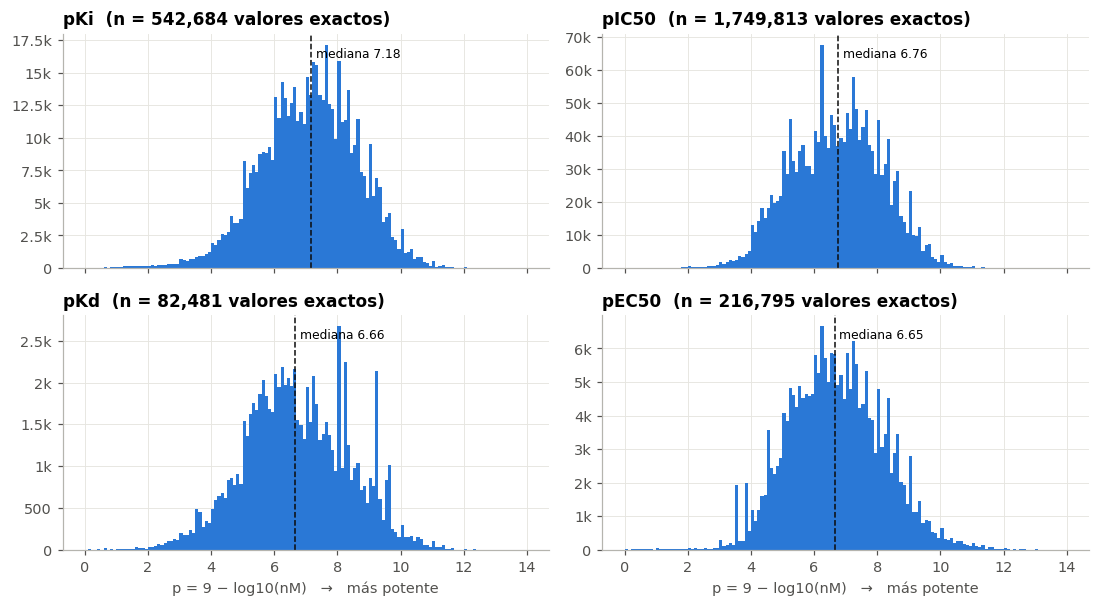

,count,mean,std,min,1%,5%,25%,50%,75%,95%,99%,max
Ki,542684.0,7.11,1.51,-0.48,3.24,4.64,6.11,7.18,8.16,9.46,10.33,14.45
IC50,1749813.0,6.72,1.43,-3.66,3.56,4.38,5.68,6.76,7.74,9.00,9.80,13.30
Kd,82481.0,6.74,1.66,-0.54,2.92,4.07,5.59,6.66,8.00,9.48,10.40,15.00
EC50,216795.0,6.70,1.50,-1.05,3.52,4.37,5.63,6.65,7.72,9.13,10.38,15.85


In [12]:
P = {}
for t in TIPOS:
    m = bd[f"{t}_qual"].isna() & (bd[t] > 0)
    P[t] = 9 - np.log10(bd.loc[m, t].to_numpy())

fig, axes = plt.subplots(2, 2, figsize=(10, 5.6), sharex=True)
bins = np.arange(0, 14.01, 0.1)
for ax, t in zip(axes.flat, TIPOS):
    ax.hist(P[t], bins=bins, color=AZUL, edgecolor="none")
    med = np.median(P[t])
    ax.axvline(med, color="#0b0b0b", lw=1, ls="--")
    ax.text(med + 0.15, ax.get_ylim()[1] * 0.9, f"mediana {med:.2f}", fontsize=8)
    ax.set_title(f"p{t}  (n = {len(P[t]):,} valores exactos)")
    ax.yaxis.set_major_formatter(mticker.FuncFormatter(lambda v, _: f"{v/1e3:g}k" if v >= 1e3 else f"{v:.0f}"))
for ax in axes[1]:
    ax.set_xlabel("p = 9 − log10(nM)   →   más potente")
guardar(fig, "05_distribucion_p")

resumen_p = pd.DataFrame({t: pd.Series(P[t]).describe(percentiles=[.01, .05, .25, .5, .75, .95, .99]) for t in TIPOS}).T
display(resumen_p.round(2))
H["Mediana pIC50 / pKi (valores exactos)"] = f"{np.median(P['IC50']):.2f} / {np.median(P['Ki']):.2f}"

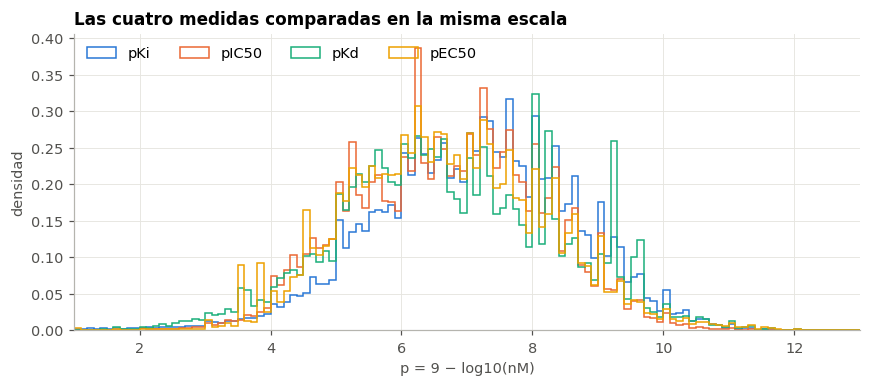

In [13]:
fig, ax = plt.subplots(figsize=(8, 3.6))
for t, c in zip(TIPOS, CAT):
    ax.hist(P[t], bins=bins, density=True, histtype="step", lw=2, color=c, label=f"p{t}")
ax.set_xlim(1, 13); ax.set_xlabel("p = 9 − log10(nM)"); ax.set_ylabel("densidad")
ax.legend(ncol=4, loc="upper left")
ax.set_title("Las cuatro medidas comparadas en la misma escala")
guardar(fig, "05_distribucion_p_comparada")

**Interpretación.**

- Las distribuciones son **unimodales** y se centran alrededor de p ≈ 6–7 (1 µM – 100 nM), el rango típico de compuestos de química medicinal. La cola derecha (p > 9, sub-nM) corresponde a compuestos optimizados.
- Se ven **picos en valores redondos** (p = 4, 5, 6…). Son cortes de ensayo que no llevan calificador, y valores reportados redondeados.
- **pKi suele estar ligeramente a la derecha de pIC50**. Es coherente con Cheng–Prusoff, que da Ki ≤ IC50 en inhibición competitiva [5], y con el factor ~2 que reportan Kalliokoski *et al.* [11]. En la sección 9 se compara Ki contra IC50 *para el mismo par*.
- **EC50** es funcional y mide otra cosa que una constante de unión [7], así que no debe mezclarse sin cuidado con las demás.

### Valores extremos o físicamente dudosos

In [14]:
ext = []
for t in TIPOS:
    v = bd.loc[bd[f"{t}_qual"].isna(), t].dropna()
    ext.append({"tipo": t, "≤ 0": int((v <= 0).sum()),
                "< 1 pM (p > 12)": int((v < 1e-3).sum()),
                "> 10 mM (p < 2)": int((v > 1e7).sum()),
                "mín (nM)": v[v > 0].min(), "máx (nM)": v.max()})
display(pd.DataFrame(ext).set_index("tipo"))
print("Ejemplos de IC50 > 10 mM:")
display(bd.loc[bd["IC50"] > 1e7, ["inchikey", "target", "IC50", "source", "doi", "patent"]].head(5))

,≤ 0,< 1 pM (p > 12),> 10 mM (p < 2),mín (nM),máx (nM)
tipo,,,,,
Ki,26,109,1528,3.550000e-06,3.000000e+09
IC50,144,189,1820,5.000000e-05,4.527050e+12
Kd,32,51,149,1.000000e-06,3.492000e+09
EC50,12,81,293,1.400000e-07,1.132000e+10


Ejemplos de IC50 > 10 mM:


,inchikey,target,IC50,source,doi,patent
8469,MJMLUICFHWSBQZ-UHFFFAOYSA-N,Neuraminidase,20000000.0,Curated from the literature by BindingDB,10.1016/s0960-894x(99)00318-2,<NA>
26786,NBIIXXVUZAFLBC-UHFFFAOYSA-N,Proto-oncogene tyrosine-protein kinase Src [145-252],40000000.0,Curated from the literature by BindingDB,10.1021/jm020970s,<NA>
26787,KRKNYBCHXYNGOX-UHFFFAOYSA-N,Proto-oncogene tyrosine-protein kinase Src [145-252],40000000.0,Curated from the literature by BindingDB,10.1021/jm020970s,<NA>
26788,OFOBLEOULBTSOW-UHFFFAOYSA-N,Proto-oncogene tyrosine-protein kinase Src [145-252],40000000.0,Curated from the literature by BindingDB,10.1021/jm020970s,<NA>
26789,MUBZPKHOEPUJKR-UHFFFAOYSA-N,Proto-oncogene tyrosine-protein kinase Src [145-252],40000000.0,Curated from the literature by BindingDB,10.1021/jm020970s,<NA>


**Interpretación.** La especificación exige valores > 0 [2]. Afinidades por debajo de 1 pM son químicamente posibles pero muy raras, y por encima de 10 mM suelen indicar compuestos inactivos o errores de unidades en la fuente. Son pocas filas, pero conviene **tenerlas identificadas** antes de cualquier análisis.

### Datos cinéticos: kon y koff

`Kd = koff/kon` y el tiempo de residencia es `1/koff` [8][9].

Filas con kon: 1,003 | con koff: 1,019 | con ambos: 246


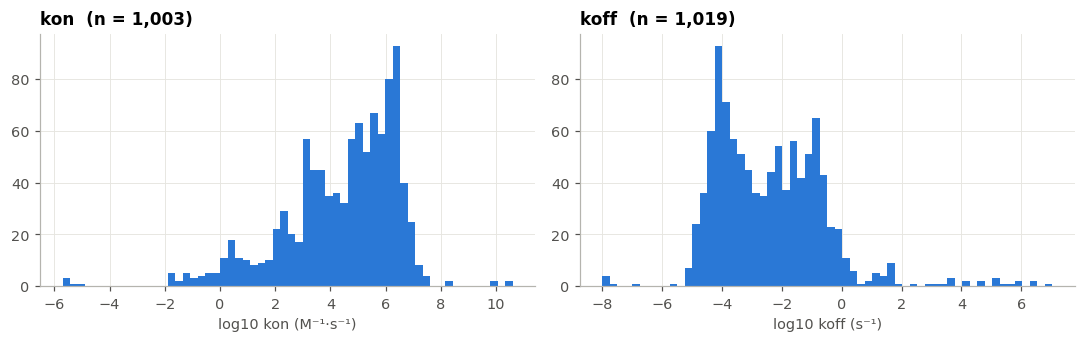

,Kd_cinetica_nM,residencia_min
count,2.460000e+02,246.000
mean,1.092044e+14,217.550
std,8.004364e+14,631.003
min,4.300000e-02,0.000
25%,5.760000e+00,4.666
50%,8.718600e+01,27.344
75%,1.115607e+03,169.583
max,1.032765e+16,8051.530


Filas con Kd reportada y kon/koff: 37; correlación log10(Kd reportada) vs log10(koff/kon): r = 0.679


In [15]:
print(f"Filas con kon: {bd['kon'].notna().sum():,} | con koff: {bd['koff'].notna().sum():,} | "
      f"con ambos: {(bd['kon'].notna() & bd['koff'].notna()).sum():,}")

fig, axes = plt.subplots(1, 2, figsize=(10, 3.2))
for ax, c, u in zip(axes, ["kon", "koff"], ["M⁻¹·s⁻¹", "s⁻¹"]):
    v = bd[c].dropna(); v = v[v > 0]
    ax.hist(np.log10(v), bins=60, color=AZUL)
    ax.set_xlabel(f"log10 {c} ({u})"); ax.set_title(f"{c}  (n = {len(v):,})")
guardar(fig, "05_cinetica")

ambos = bd.loc[bd["kon"].gt(0) & bd["koff"].gt(0), ["kon", "koff", "Kd", "Kd_qual"]].copy()
ambos["Kd_cinetica_nM"] = ambos["koff"] / ambos["kon"] * 1e9
ambos["residencia_min"] = 1 / ambos["koff"] / 60
display(ambos[["Kd_cinetica_nM", "residencia_min"]].describe().round(3))
emparejado = ambos.dropna(subset=["Kd"]).query("Kd > 0")
if len(emparejado) > 10:
    r = np.corrcoef(np.log10(emparejado["Kd"]), np.log10(emparejado["Kd_cinetica_nM"]))[0, 1]
    print(f"Filas con Kd reportada y kon/koff: {len(emparejado):,}; "
          f"correlación log10(Kd reportada) vs log10(koff/kon): r = {r:.3f}")

**Interpretación.** Los kon de moléculas pequeñas suelen caer entre 10⁴ y 10⁸ M⁻¹s⁻¹, y los koff abarcan muchos órdenes de magnitud. Esto es lo que hace que **dos compuestos con la misma Kd puedan tener tiempos de residencia muy distintos** [9]. Si la fila trae Kd *y* kon/koff, la Kd reportada debería coincidir aproximadamente con koff/kon [8]. En los datos, la Kd derivada de koff/kon tiene una cola de valores **absurdamente altos** (muy por encima de 1 M), y la correlación con la Kd reportada es solo moderada, sobre muy pocas filas. Eso apunta a **unidades inconsistentes** en algunos registros cinéticos, por ejemplo kon reportado en otra escala de tiempo [8]. Si se usan, conviene validarlos uno por uno.

# <div style="border-left:4px solid #3D6FB0;padding:4px 0 6px 14px;margin:16px 0 6px 0;"><span style="color:#3D6FB0;font-size:21px;font-weight:700;">6. Fuentes de los datos y evolución en el tiempo</span></div>

### Origen por medición

Valores esperados de `Curation/DataSource` [2][3]:

- *Curated from the literature by BindingDB*: artículos extraídos manualmente por el equipo.
- *US Patent* / *WIPO*: patentes de EE. UU. e internacionales, curadas por BindingDB. Son el motor del crecimiento reciente [4].
- *ChEMBL*: importado de ChEMBL, solo targets proteicos [3].
- *PubChem*: BioAssays confirmatorios [3].
- *PDSP Ki*: base de Ki del NIMH PDSP [26].
- *CSAR*: conjuntos de referencia para *docking* y *scoring* [27].
- *D3R* (*Drug Design Data Resource*): datos de los retos ciegos de predicción de poses y afinidades, en su mayoría aportados por la industria [29].
- Otros: datos depositados por grupos (p. ej. *Taylor Research Group, UCSD*).

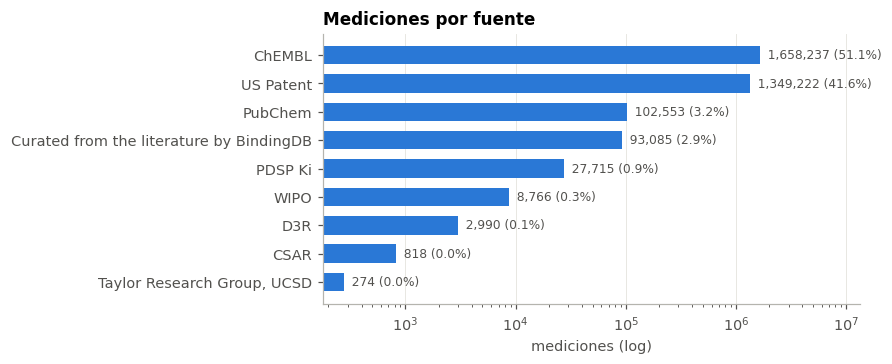

In [16]:
src = bd["source"].value_counts()
fig, ax = plt.subplots(figsize=(8, 3.4))
s = src.sort_values()
ax.barh(s.index.astype(str), s.values, color=AZUL, height=0.65)
for y, v in enumerate(s.values):
    ax.text(v, y, f"  {v:,} ({pct(v, n):.1f}%)", va="center", fontsize=8, color="#52514e")
ax.set_xscale("log"); ax.set_xlim(right=s.max() * 8); ax.grid(axis="y", visible=False)
ax.set_xlabel("mediciones (log)"); ax.set_title("Mediciones por fuente")
guardar(fig, "06_fuentes")
H["Fuente principal"] = f"{src.index[0]} ({pct(src.iloc[0], n):.1f}%)"

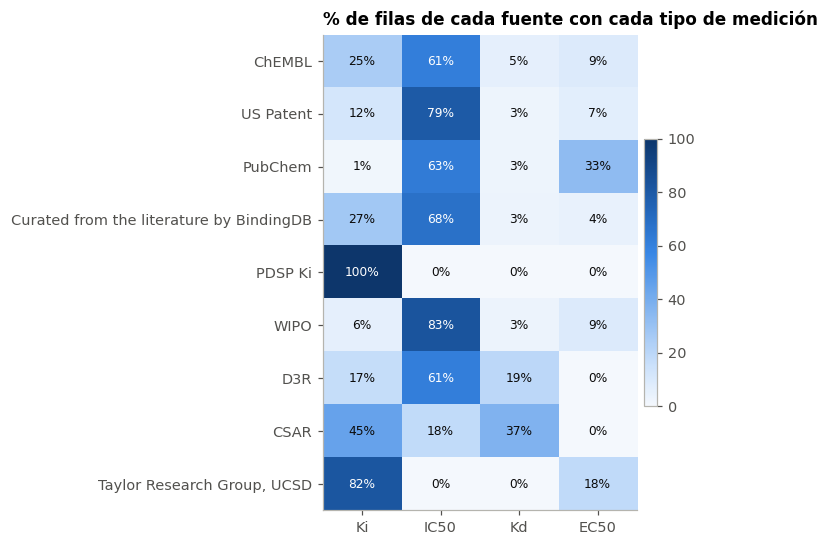

In [17]:
mezcla = (100 * presente[TIPOS].groupby(bd["source"], observed=True).mean()).loc[src.index]
fig, ax = plt.subplots(figsize=(6.5, 0.45 * len(mezcla) + 1))
im = ax.imshow(mezcla.values, cmap=SEQ_CMAP, vmin=0, vmax=100, aspect="auto")
ax.set_xticks(range(len(TIPOS)), TIPOS); ax.set_yticks(range(len(mezcla)), mezcla.index.astype(str))
for (i, j), v in np.ndenumerate(mezcla.values):
    ax.text(j, i, f"{v:.0f}%", ha="center", va="center", fontsize=8, color="white" if v > 55 else "#0b0b0b")
ax.grid(False); ax.set_title("% de filas de cada fuente con cada tipo de medición")
fig.colorbar(im, ax=ax, fraction=0.04, pad=0.02)
guardar(fig, "06_fuente_vs_tipo")

**Interpretación.** Cada fuente tiene un "perfil" de medición distinto: **PDSP** es casi solo Ki (es una base de Ki [26]), las **patentes** son mayoritariamente IC50, y **PubChem** y **ChEMBL** mezclan varias. Es decir, **el tipo de afinidad está confundido con la fuente**: comparar IC50 contra Ki es, en parte, comparar patentes contra literatura académica.

### Evolución temporal

Hay dos fechas: la **publicación** del artículo o patente y el **ingreso a BindingDB** [2].

Fechas de publicación válidas: 97.3% | rango 1965–2026
Fechas de ingreso válidas    : 100.0% | rango 2000–2026
Publicación posterior al ingreso (inconsistente): 3,313 filas


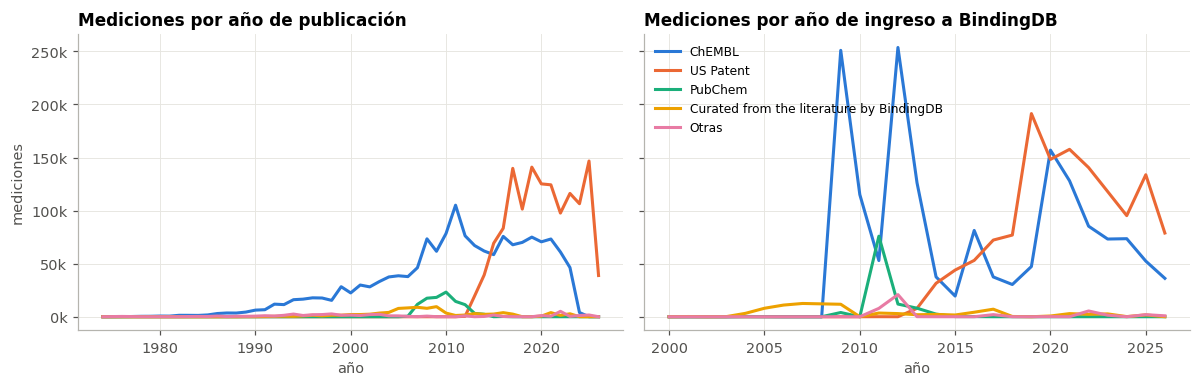

In [18]:
anio_pub = bd["pub_date"].dt.year
anio_bdb = bd["bdb_date"].dt.year
print(f"Fechas de publicación válidas: {pct(anio_pub.notna().sum(), n):.1f}% | rango {anio_pub.min():.0f}–{anio_pub.max():.0f}")
print(f"Fechas de ingreso válidas    : {pct(anio_bdb.notna().sum(), n):.1f}% | rango {anio_bdb.min():.0f}–{anio_bdb.max():.0f}")
print(f"Publicación posterior al ingreso (inconsistente): {(bd['pub_date'] > bd['bdb_date']).sum():,} filas")

top_src = src.index[:4].tolist()
grupo = bd["source"].astype("object").where(bd["source"].isin(top_src), "Otras")
fig, axes = plt.subplots(1, 2, figsize=(11, 3.6), sharey=True)
for ax, anio, titulo in [(axes[0], anio_pub, "por año de publicación"), (axes[1], anio_bdb, "por año de ingreso a BindingDB")]:
    tab = pd.crosstab(anio, grupo).loc[1970:2026]
    for c, color in zip(top_src + ["Otras"], CAT):
        if c in tab:
            ax.plot(tab.index, tab[c], color=color, lw=2, label=c)
    ax.set_title(f"Mediciones {titulo}"); ax.set_xlabel("año")
    ax.yaxis.set_major_formatter(mticker.FuncFormatter(lambda v, _: f"{v/1e3:.0f}k"))
axes[0].set_ylabel("mediciones")
axes[1].legend(loc="upper left", fontsize=8)
guardar(fig, "06_tiempo")

**Interpretación.** El volumen crece fuertemente a partir de los 2000 y las **patentes** dominan los años recientes, como describe el artículo de 2024 [4]. Los picos en el año de ingreso corresponden a **importaciones masivas**, como una nueva versión de ChEMBL o un lote de patentes, no a "descubrimientos" de ese año.

### Documentos e instituciones

,distintos
Entradas BindingDB (Entry DOI),"57,177"
Artículos (DOI),"41,716"
Artículos (PMID),"45,550"
Patentes,"8,991"
BioAssays PubChem (AID),"15,246"
Instituciones,"9,221"


Prefijo de patente: {'US': 1346871, 'WO': 8766, 'USRE': 2351}
Mediciones por entrada BindingDB: mediana 26, p95 184, máx 31,824


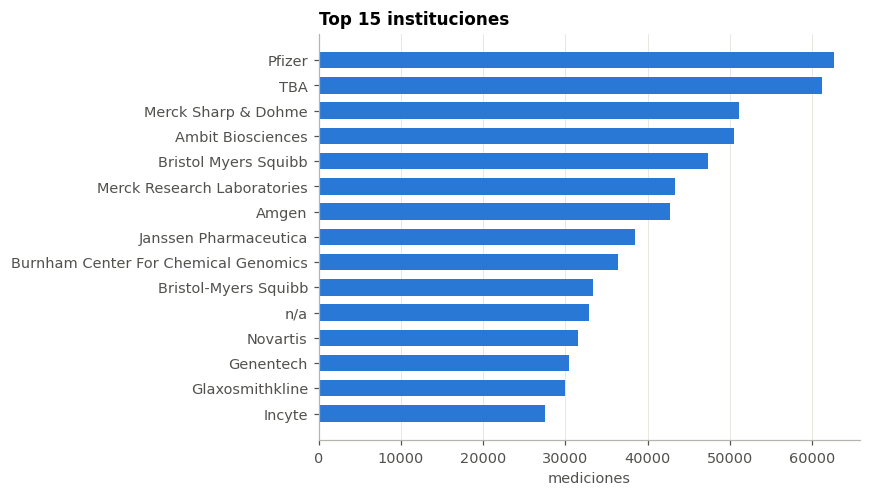

In [19]:
docs = pd.Series({
    "Entradas BindingDB (Entry DOI)": bd["entry_doi"].nunique(),
    "Artículos (DOI)": bd["doi"].nunique(),
    "Artículos (PMID)": bd["pmid"].nunique(),
    "Patentes": bd["patent"].nunique(),
    "BioAssays PubChem (AID)": bd["aid"].nunique(),
    "Instituciones": bd["institution"].nunique(),
})
display(docs.to_frame("distintos").style.format("{:,}"))
prefijo = bd["patent"].astype("object").str.extract(r"^([A-Z]+)", expand=False).value_counts()
print("Prefijo de patente:", prefijo.head(6).to_dict())
por_doc = bd.groupby("entry_doi", observed=True).size()
print(f"Mediciones por entrada BindingDB: mediana {por_doc.median():.0f}, p95 {por_doc.quantile(.95):.0f}, máx {por_doc.max():,}")

inst = bd["institution"].value_counts().head(15).sort_values()
fig, ax = plt.subplots(figsize=(8, 4.6))
ax.barh(inst.index.astype(str).str.slice(0, 55), inst.values, color=AZUL, height=0.65)
ax.grid(axis="y", visible=False); ax.set_xlabel("mediciones"); ax.set_title("Top 15 instituciones")
guardar(fig, "06_instituciones")

**Interpretación.** Una sola entrada (un artículo o una patente) aporta en promedio decenas de mediciones: típicamente una **serie química** de análogos medida contra uno o pocos targets. Las instituciones top son mayoritariamente **farmacéuticas**, consecuencia directa del peso de las patentes.

# <div style="border-left:4px solid #3D6FB0;padding:4px 0 6px 14px;margin:16px 0 6px 0;"><span style="color:#3D6FB0;font-size:21px;font-weight:700;">7. Ligandos (moléculas pequeñas)</span></div>

Se trabaja a nivel de **ligando único**, definido por el **InChIKey** completo (sección 0.1, *Identidad del ligando*).

### Anatomía del InChIKey: verificación del formato

Se comprueba en los datos la forma `14 letras – 8 letras + S/N + A – P` [13][14].

In [20]:
lig_code, lig_uniq = pd.factorize(bd["inchikey"])
keys = pd.Series(lig_uniq.astype(object))
ok = keys.str.fullmatch(r"[A-Z]{14}-[A-Z]{8}[SN][A-Z]-[A-Z]")
print(f"Ligandos únicos (InChIKey): {len(keys):,} | formato válido: {pct(ok.sum(), len(keys)):.3f}%")
print("Bandera estándar/no estándar (car. 24):", keys.str[23].value_counts().to_dict())
print("Versión (car. 25):", keys.str[24].value_counts().to_dict())
print("Protonación (car. 27; N = neutro):", keys.str[26].value_counts().head(6).to_dict())
print(f"InChI con prefijo estándar 'InChI=1S/': {pct(bd['inchi_std'].sum(), bd['inchi_std'].notna().sum()):.2f}% de filas con InChI")

esq = keys.str[:14]
grupos = esq.value_counts()
print(f"\nEsqueletos (primer bloque) distintos: {len(grupos):,}; con >1 InChIKey: {(grupos > 1).sum():,}")
bloque2 = keys.str[15:23].groupby(esq).nunique()
ejemplo = grupos[grupos.index.isin(bloque2[bloque2 > 1].index)].index[0]
smi_por_key = pd.Series(bd["smiles"].to_numpy(), index=lig_code).groupby(level=0).first().drop(-1, errors="ignore")
print(f"Ejemplo de esqueleto con {grupos[ejemplo]} variantes ({ejemplo}): mismas conexiones, distinto segundo bloque (estereo/isótopos)")
display(pd.DataFrame({"InChIKey": keys[esq == ejemplo].head(4).values,
                      "SMILES": smi_por_key.loc[keys[esq == ejemplo].head(4).index].values}))
solo_prot = (keys.str[:25].groupby(esq).nunique() == 1) & (grupos.reindex(bloque2.index) > 1)
print(f"Esqueletos cuyas variantes difieren solo en protonación (último carácter): {solo_prot.sum():,}")

Ligandos únicos (InChIKey): 1,354,629 | formato válido: 100.000%
Bandera estándar/no estándar (car. 24): {'S': 1354629}
Versión (car. 25): {'A': 1354629}
Protonación (car. 27; N = neutro): {'N': 1343795, 'O': 4471, 'M': 4032, 'L': 907, 'P': 480, 'K': 357}
InChI con prefijo estándar 'InChI=1S/': 100.00% de filas con InChI

Esqueletos (primer bloque) distintos: 1,341,216; con >1 InChIKey: 10,862
Ejemplo de esqueleto con 13 variantes (JAWZHQVSWRRVSQ): mismas conexiones, distinto segundo bloque (estereo/isótopos)


,InChIKey,SMILES
0,JAWZHQVSWRRVSQ-QZNYNHHHSA-N,CNc1cc(nc2c(cnn12)C(=O)NC1CC[C@H]1O)-c1cnc2n(cccc12)[C@H]1COC[C@@H]1OC
1,JAWZHQVSWRRVSQ-FFGOWVMKSA-N,CNc1cc(nc2c(cnn12)C(=O)N[C@H]1CC[C@H]1O)-c1cnc2n(cccc12)[C@H]1COC[C@@H]1OC
2,JAWZHQVSWRRVSQ-GTAWCEEGSA-N,CNc1cc(nc2c(cnn12)C(=O)N[C@@H]1CC[C@@H]1O)-c1cnc2n(cccc12)[C@H]1COC[C@@H]1OC
3,JAWZHQVSWRRVSQ-FESZSOIMSA-N,CNc1cc(nc2c(cnn12)C(=O)NC1CC[C@H]1O)-c1cnc2n(cccc12)[C@@H]1COC[C@H]1OC


Esqueletos cuyas variantes difieren solo en protonación (último carácter): 961


**Interpretación.**

- Cuando dos InChIKey comparten el primer bloque pero difieren en el **segundo**, sus SMILES difieren en los símbolos `@`/`@@` o `/` `\`, es decir, en la **estereoquímica**. Eso es lo que codifica ese bloque [13]. Para BindingDB los estereoisómeros son compuestos distintos, y es correcto: pueden tener afinidades muy diferentes.
- Cuando difieren solo en el **último carácter**, la diferencia es de **protonación**: la misma molécula registrada neutra (`N`) o como sal o ion con protones añadidos o quitados (p. ej. un carboxilato `[O-]`) [13][14]. Químicamente es "el mismo compuesto" en otro estado de ionización, así que para muchos análisis conviene agruparlos por los primeros 25 caracteres.

### Número de mediciones por ligando

,mediciones por ligando,targets por ligando
count,1354629.00,1354629.00
mean,2.39,1.68
std,8.93,4.01
min,1.00,1.00
50%,1.00,1.00
90%,4.00,3.00
99%,13.00,7.00
max,3260.00,1934.00


Ligandos medidos una sola vez: 50.4%
Ligandos probados contra un solo target: 66.0%


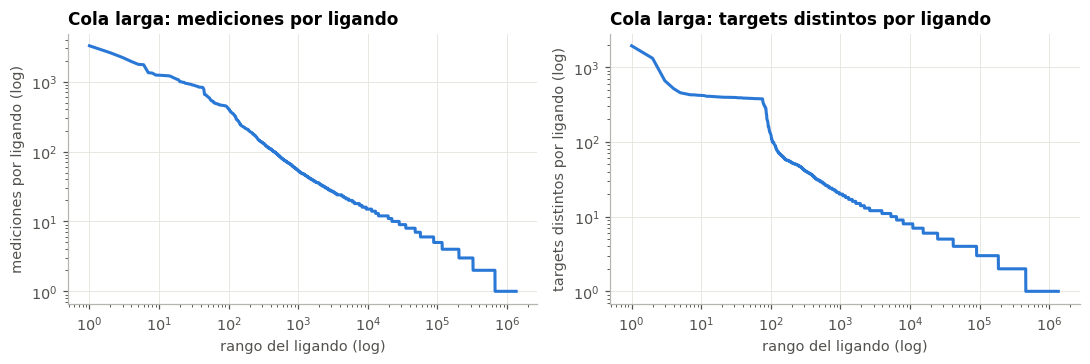

In [21]:
valido = lig_code >= 0
med_por_lig = np.bincount(lig_code[valido])
tcode = bd["target"].cat.codes.to_numpy()
pares = pd.DataFrame({"l": lig_code, "t": tcode})[valido & (tcode >= 0)].drop_duplicates()
tgt_por_lig = np.bincount(pares["l"], minlength=len(keys))

desc = pd.DataFrame({"mediciones por ligando": pd.Series(med_por_lig).describe(percentiles=[.5, .9, .99]),
                     "targets por ligando": pd.Series(tgt_por_lig).describe(percentiles=[.5, .9, .99])})
display(desc.round(2))
print(f"Ligandos medidos una sola vez: {pct((med_por_lig == 1).sum(), len(med_por_lig)):.1f}%")
print(f"Ligandos probados contra un solo target: {pct((tgt_por_lig == 1).sum(), len(tgt_por_lig)):.1f}%")
H["Ligandos con un solo target"] = f"{pct((tgt_por_lig == 1).sum(), len(tgt_por_lig)):.1f}%"

fig, axes = plt.subplots(1, 2, figsize=(10, 3.4))
for ax, v, t in [(axes[0], med_por_lig, "mediciones por ligando"), (axes[1], tgt_por_lig, "targets distintos por ligando")]:
    r = np.sort(v)[::-1]
    ax.loglog(np.arange(1, len(r) + 1), r, color=AZUL, lw=2)
    ax.set_xlabel("rango del ligando (log)"); ax.set_ylabel(t + " (log)"); ax.set_title(f"Cola larga: {t}")
guardar(fig, "07_cola_larga_ligandos")

**Interpretación.** Es una distribución de **cola larga**. La gran mayoría de ligandos aparece en pocas mediciones y contra **un solo target**: son análogos sintetizados para *un* proyecto y reportados en *un* artículo o patente. En el otro extremo están los **inhibidores de referencia promiscuos**, como la estaurosporina (código HET `STO`, sección 11), el ligando más medido, e inhibidores de cinasas aprobados como sunitinib o sorafenib (BAY 43-9006). Se miden contra cientos de targets en **paneles de selectividad**. Algunos compuestos de ChEMBL aparecen contra más de mil targets distintos con una sola medición cada uno: son perfiles de panel completos.

In [22]:
top_lig = (pd.DataFrame({"InChIKey": keys, "mediciones": med_por_lig, "targets": tgt_por_lig})
           .assign(nombre=pd.Series(bd["lig_name"].to_numpy(), index=lig_code).groupby(level=0).first().reindex(range(len(keys))).values)
           .nlargest(15, "mediciones"))
display(top_lig.reset_index(drop=True))

nn = bd["lig_n_nombres"].dropna()
print(f"Sinónimos por nombre de ligando (separados por '::'): mediana {nn.median():.0f}, máx {nn.max()}")

,InChIKey,mediciones,targets,nombre
0,HKSZLNNOFSGOKW-UHFFFAOYSA-N,3260,518,CHEMBL388978
1,BZKPWHYZMXOIDC-UHFFFAOYSA-N,2588,39,"Acetazolamide, AAZ"
2,WAEXFXRVDQXREF-UHFFFAOYSA-N,2214,65,Zolinza
3,MWKSRKSEWLRPBL-UHFFFAOYSA-N,1943,1934,CHEMBL5653589
4,WINHZLLDWRZWRT-UHFFFAOYSA-N,1772,427,SUNITINIB MALATE
5,MLDQJTXFUGDVEO-UHFFFAOYSA-N,1747,426,BAY439006
6,BMGQWWVMWDBQGC-UHFFFAOYSA-N,1345,401,PKC-412
7,ZCCPLJOKGAACRT-UHFFFAOYSA-N,1326,1316,CHEMBL3752910
8,ZBNZXTGUTAYRHI-UHFFFAOYSA-N,1240,440,N-(2-Chloro-6-methylphenyl)-2-[[6-[4-(2-hydroxyethyl)-1-piperazinyl)]-2-meth...
9,UJLAWZDWDVHWOW-UHFFFAOYSA-N,1238,403,CP-690550


Sinónimos por nombre de ligando (separados por '::'): mediana 2, máx 62


### Rasgos leídos del SMILES

Sin librerías de quimioinformática (no hay RDKit en este entorno) se pueden extraer **rasgos estructurales directamente de la gramática SMILES** [12]. Son **aproximaciones**:

- **Átomos pesados (≈ tamaño molecular)**: átomos del subconjunto orgánico fuera de corchetes más átomos entre corchetes, excluyendo hidrógenos explícitos.
- **Anillos ≈ cierres de anillo / 2**: cada anillo abre y cierra con el mismo dígito [12].
- **Átomos aromáticos**: símbolos en minúscula [12].
- **Estereocentros**: `@`/`@@`. **Geometría E/Z**: `/` `\` [12].
- **Multicomponente**: presencia de `.` (sales, contraiones o mezclas) [12].
- **Carga formal**: `+` o `-` dentro de corchetes.

,count,mean,std,min,5%,50%,95%,max
longitud SMILES,1354629.0,63.2,43.1,1.0,33.0,57.0,102.0,2115.0
átomos pesados (aprox.),1354629.0,33.2,16.1,1.0,19.0,31.0,49.0,675.0
anillos (aprox.),1354629.0,4.4,5.1,0.0,2.0,4.0,7.0,480.0
átomos aromáticos,1354629.0,16.1,6.2,0.0,6.0,16.0,26.0,384.0
estereocentros (@),1354629.0,0.9,2.4,0.0,0.0,0.0,4.0,124.0


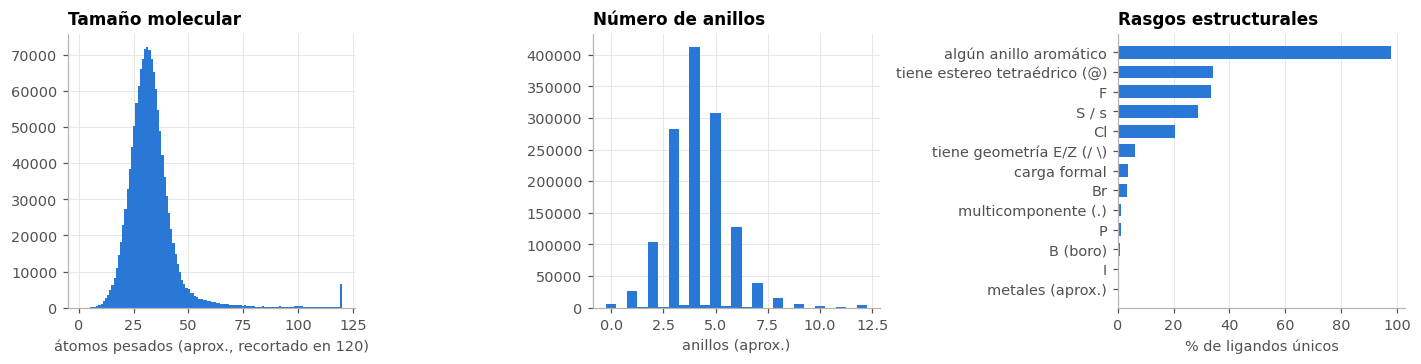

In [23]:
smi = smi_por_key.astype(object)
sin_corchetes = smi.str.replace(r"\[[^\]]*\]", "", regex=True)
corchetes = smi.str.count(r"\[[^\]]+\]")
h_explicitos = smi.str.count(r"\[\d*H[^a-z\]]*\]")
rasgos = pd.DataFrame({
    "longitud SMILES": smi.str.len(),
    "átomos pesados (aprox.)": sin_corchetes.str.count(r"Cl|Br|[BCNOPSFI]|[bcnops]") + corchetes - h_explicitos,
    "anillos (aprox.)": sin_corchetes.str.count(r"%\d\d|\d") / 2,
    "átomos aromáticos": sin_corchetes.str.count(r"[cnops]") + smi.str.count(r"\[\d*[cnops][^\]]*\]"),
    "estereocentros (@)": smi.str.count(r"@{1,2}"),
})
display(rasgos.describe(percentiles=[.05, .5, .95]).T.round(1))

bandera = pd.Series({
    "tiene estereo tetraédrico (@)": (rasgos["estereocentros (@)"] > 0).mean(),
    "tiene geometría E/Z (/ \\)": smi.str.contains(r"[/\\]").mean(),
    "multicomponente (.)": smi.str.contains(".", regex=False).mean(),
    "carga formal": smi.str.contains(r"\[[^\]]*[+-][^\]]*\]").mean(),
    "algún anillo aromático": (rasgos["átomos aromáticos"] > 0).mean(),
    "F": smi.str.contains(r"F(?![elmr])").mean(),
    "Cl": smi.str.contains("Cl").mean(),
    "Br": smi.str.contains("Br").mean(),
    "I": smi.str.contains(r"I(?![nr])").mean(),
    "S / s": smi.str.contains(r"S(?![ebinrcmg])|s(?![e])").mean(),
    "P": smi.str.contains(r"P(?![bdmortu])").mean(),
    "B (boro)": smi.str.contains(r"B(?![aeihkr])").mean(),
    "metales (aprox.)": smi.str.contains(r"\[\d*(?:Li|Na|K|Mg|Ca|Fe|Zn|Cu|Co|Ni|Mn|Pt|Pd|Ru|Rh|Ir|Au|Ag|Hg|Sn|Gd|Ga|V|Cr|Mo|W|Re|Os|Tc)[^a-z]").mean(),
}) * 100
H["Ligandos con estereocentros"] = f"{bandera['tiene estereo tetraédrico (@)']:.1f}%"

fig, axes = plt.subplots(1, 3, figsize=(13, 3.4))
axes[0].hist(rasgos["átomos pesados (aprox.)"].clip(upper=120), bins=120, color=AZUL)
axes[0].set_xlabel("átomos pesados (aprox., recortado en 120)"); axes[0].set_title("Tamaño molecular")
axes[1].hist(rasgos["anillos (aprox.)"].clip(upper=12), bins=np.arange(-0.25, 12.5, 0.5), color=AZUL)
axes[1].set_xlabel("anillos (aprox.)"); axes[1].set_title("Número de anillos")
b = bandera.sort_values()
axes[2].barh(b.index, b.values, color=AZUL, height=0.65); axes[2].grid(axis="y", visible=False)
axes[2].set_xlabel("% de ligandos únicos"); axes[2].set_title("Rasgos estructurales")
guardar(fig, "07_rasgos_smiles")

**Interpretación.**

- El tamaño típico ronda **25–35 átomos pesados**, el rango de las moléculas *drug-like* (≈ 350–500 Da). La cola derecha corresponde a péptidos, macrociclos y productos naturales.
- La mayoría tiene **2–4 anillos** y **anillos aromáticos**, rasgos característicos de la química medicinal.
- **F y Cl** son muy frecuentes: la halogenación es una estrategia habitual para modular metabolismo y afinidad.
- Los SMILES con `.` (multicomponente) contienen **sales o contraiones**. Para muchos usos conviene quedarse con el componente principal.

### Identificadores externos

Para cada ID se calcula qué % de ligandos únicos lo tiene, y se **verifica el formato** contra el patrón documentado (sección 0.1, *Identificadores externos del ligando*).

In [24]:
FORMATO = {"id_cid": r"\d+", "id_sid": r"\d+", "id_chebi": r"(?:CHEBI:)?\d+", "id_chembl": r"CHEMBL\d+",
           "id_drugbank": r"DB\d{5}", "id_iuphar": r"\d+", "id_kegg": r"[CD]\d{5}", "id_zinc": r"ZINC\d+",
           "het": r"[A-Z0-9]{1,3}|[A-Z0-9]{5}"}
filas = []
for c, rx in FORMATO.items():
    tiene = pd.Series(bd[c].notna().to_numpy())[valido].groupby(lig_code[valido]).any()
    vals = pd.Series(bd[c].dropna().astype(object).unique())
    okf = vals.str.fullmatch(rx)
    filas.append({"columna": c, "% ligandos con ID": round(100 * tiene.mean(), 2),
                  "valores distintos": len(vals), "% formato esperado": round(100 * okf.mean(), 2),
                  "ejemplo": vals.iloc[0] if len(vals) else "",
                  "ejemplo fuera de formato": vals[~okf].iloc[0] if (~okf).any() else ""})
ids = pd.DataFrame(filas).set_index("columna")
display(ids)
H["Ligandos con DrugBank ID"] = f"{ids.loc['id_drugbank', '% ligandos con ID']}%"

,% ligandos con ID,valores distintos,% formato esperado,ejemplo,ejemplo fuera de formato
columna,,,,,
id_cid,97.50,1390645,100.00,3009304,
id_sid,97.50,1409615,100.00,483500124,
id_chebi,0.05,674,100.00,16136,
id_chembl,30.04,427699,99.35,CHEMBL287355,CHEMBL2021323CHEMBL2021324
id_drugbank,0.19,2616,100.00,DB06910,
id_iuphar,0.01,139,100.00,5661,
id_kegg,1.39,3068,100.00,C15660,
id_zinc,1.31,17653,100.00,ZINC03234246,
het,0.80,11082,100.00,638,


**Interpretación.**

- **PubChem CID** cubre casi todo: PubChem agrega estructuras de cientos de depositantes [19].
- **ChEMBL ID** cubre buena parte, porque gran parte del contenido proviene de ChEMBL [3][4].
- **DrugBank, KEGG, IUPHAR y ChEBI** cubren una fracción pequeña. Estas bases solo incluyen **fármacos, metabolitos o ligandos farmacológicos de referencia** [21][22][23][25], así que su presencia sirve como **marcador de "compuesto conocido"** frente a "análogo de patente".
- Los "ejemplos fuera de formato" muestran que algunas celdas contienen **varios IDs pegados sin separador** (p. ej. `CHEMBL2021323CHEMBL2021324`): un mismo ligando quedó asociado a más de un registro de la otra base. Al unir con ChEMBL o con otras bases hay que **separarlos** primero, por ejemplo con `re.findall(r"CHEMBL\d+", ...)`.
- El último carácter del InChIKey (sección 7.1) también es informativo: `N` = neutro, y las demás letras indican protones añadidos o quitados respecto a la forma neutra [13].

# <div style="border-left:4px solid #3D6FB0;padding:4px 0 6px 14px;margin:16px 0 6px 0;"><span style="color:#3D6FB0;font-size:21px;font-weight:700;">8. Targets (proteínas)</span></div>

### Nombres, construcciones y proteínas canónicas

`Target Name` añade anotaciones `[rango, mutación]` al nombre UniProt [2]. Se mide cuántos nombres hay por proteína y qué tipo de anotaciones aparecen.

In [25]:
nombres_t = pd.Series(bd["target"].cat.categories.astype(object))
filas_por_nombre = np.bincount(tcode[tcode >= 0], minlength=len(nombres_t))
anot = nombres_t.str.extract(r"\[(.*)\]\s*$", expand=False)
AA = "ACDEFGHIKLMNPQRSTVWY"
clase = pd.DataFrame({
    "con anotación [..]": anot.notna(),
    "rango de residuos (a-b)": anot.str.contains(r"\d+\s*-\s*\d+", na=False),
    "mutación puntual (X123Y)": anot.str.contains(rf"\b[{AA}]\d{{1,4}}[{AA}]\b", na=False),
    "deleción (del)": anot.str.contains(r"del", case=False, na=False),
})
tab = pd.DataFrame({"% de nombres distintos": 100 * clase.mean(),
                    "% de mediciones": 100 * clase.mul(filas_por_nombre, axis=0).sum() / filas_por_nombre.sum()})
display(tab.round(2))
print("Ejemplos de anotaciones:", anot.dropna().sample(8, random_state=0).tolist())

up_t = bd[["uniprot1", "target"]].dropna().drop_duplicates()
nombres_por_up = up_t.groupby("uniprot1", observed=True).size()
print(f"\nNombres de target por accession UniProt: mediana {nombres_por_up.median():.0f}, "
      f"máx {nombres_por_up.max()} ({nombres_por_up.idxmax()})")
display(up_t[up_t["uniprot1"] == nombres_por_up.idxmax()]["target"].head(8).to_frame())
H["Mediciones con target mutante/truncado"] = f"{tab.loc['con anotación [..]', '% de mediciones']:.1f}%"

,% de nombres distintos,% de mediciones
con anotación [..],16.51,6.47
rango de residuos (a-b),11.83,4.02
mutación puntual (X123Y),8.70,3.03
deleción (del),0.00,0.00


Ejemplos de anotaciones: ['G12V,1-166]/Son of sevenless homolog 1 [564-1049', '147-515', 'A217G', '197-447', 'A1275T', 'L858R,T790M,C797S', '44-168', '177-447']

Nombres de target por accession UniProt: mediana 1, máx 60 (P00533)


,target
3774,Epidermal growth factor receptor
47428,"Epidermal growth factor receptor [696-1022,G719S]"
47430,"Epidermal growth factor receptor [696-1022,L858R]"
47434,"Epidermal growth factor receptor [696-1022,T790M]"
47438,"Epidermal growth factor receptor [696-1022,T790M,L858R]"
51090,"Epidermal growth factor receptor [671-1210,L858R]"
57373,Epidermal growth factor receptor [668-1210]
57377,"Epidermal growth factor receptor [696-1210,T790M]"


**Interpretación.** Una misma proteína UniProt aparece con **muchos nombres** porque se midieron distintas **construcciones**: dominios aislados (p. ej. solo el dominio cinasa), mutantes de resistencia (como EGFR T790M) o versiones con mutaciones estabilizantes [2]. `Target Name` es, por tanto, más fino que "proteína". Para agrupar por proteína se usa la **accession UniProt**, el identificador estable [15].

### Organismos y especie según UniProt

Organismos distintos: 758 | Homo sapiens: 76.6% de las mediciones


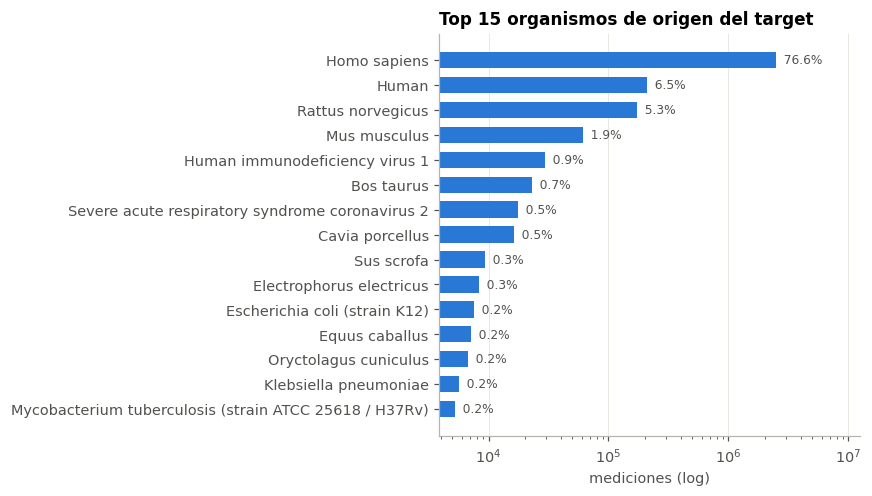

Código de especie en el entry name Swiss-Prot (X_Y) [15]: {'HUMAN': 5126, 'MOUSE': 859, 'RAT': 821, 'BOVIN': 194, 'ECOLI': 143, 'MYCTU': 93, 'PIG': 88, 'YEAST': 76}


In [26]:
org = bd["organism"].value_counts()
print(f"Organismos distintos: {len(org):,} | Homo sapiens: {pct(org.get('Homo sapiens', 0), n):.1f}% de las mediciones")
H["% mediciones en proteínas humanas"] = f"{pct(org.get('Homo sapiens', 0), n):.1f}%"

o15 = org.head(15).sort_values()
fig, ax = plt.subplots(figsize=(8, 4.6))
ax.barh(o15.index.astype(str), o15.values, color=AZUL, height=0.65)
for y, v in enumerate(o15.values):
    ax.text(v, y, f"  {pct(v, n):.1f}%", va="center", fontsize=8, color="#52514e")
ax.set_xscale("log"); ax.set_xlim(right=o15.max() * 5); ax.grid(axis="y", visible=False)
ax.set_xlabel("mediciones (log)"); ax.set_title("Top 15 organismos de origen del target")
guardar(fig, "08_organismos")

entry = pd.Series(bd["sp_entry1"].cat.categories.astype(object))
especie = entry.str.extract(r"_([A-Z0-9]+)$", expand=False).value_counts().head(8)
print("Código de especie en el entry name Swiss-Prot (X_Y) [15]:", especie.to_dict())

**Interpretación.** La gran mayoría de las mediciones son contra **proteínas humanas**, seguidas de roedores (rata, ratón: modelos preclínicos) y de patógenos (VIH, *Plasmodium*, bacterias). El sufijo del *entry name* (`_HUMAN`, `_RAT`, `_MOUSE`) es el código de especie de UniProt [15] y concuerda con la columna de organismo.

### Identificadores UniProt: Swiss-Prot frente a TrEMBL

UniProt asigna un target por **identidad de secuencia del 100 %** y el mismo organismo [2]. Swiss-Prot es la sección revisada y TrEMBL la no revisada [16].

In [27]:
tiene_sp = bd["uniprot1"].notna(); tiene_tr = bd["trembl1"].notna()
cober = pd.Series({
    "Swiss-Prot (revisada)": tiene_sp.mean(),
    "solo TrEMBL (no revisada)": (~tiene_sp & tiene_tr).mean(),
    "ninguna": (~tiene_sp & ~tiene_tr).mean(),
}) * 100
display(cober.round(2).to_frame("% de filas"))
acc = pd.Series(bd["uniprot1"].cat.categories.astype(object))
RX_UNIPROT = r"[OPQ][0-9][A-Z0-9]{3}[0-9]|[A-NR-Z][0-9](?:[A-Z][A-Z0-9]{2}[0-9]){1,2}"
print(f"Accessions distintas: {len(acc):,} | formato UniProt válido: {pct(acc.str.fullmatch(RX_UNIPROT).sum(), len(acc)):.2f}% "
      f"| longitud: {acc.str.len().value_counts().to_dict()}")
print("Ejemplos que no siguen el formato:", acc[~acc.str.fullmatch(RX_UNIPROT)].head(5).tolist())

,% de filas
Swiss-Prot (revisada),97.62
solo TrEMBL (no revisada),2.34
ninguna,0.03


Accessions distintas: 8,594 | formato UniProt válido: 99.80% | longitud: {6: 8559, 10: 18, 13: 16, 17: 1}
Ejemplos que no siguen el formato: ['B3DHD6 Q6XCC7', 'C0L093 P09114', 'O57585 A3QJX7', 'O75477 Q64133', 'P02751 P02751']


Las pocas accessions "fuera de formato" son en realidad **dos accessions en la misma celda separadas por un espacio**. Hay que separarlas antes de unir con UniProt.

Las filas **sin ninguna accession** suelen ser construcciones que no coinciden al 100 % con ninguna secuencia de UniProt (mutantes, quimeras, fragmentos con etiquetas) o proteínas de organismos poco anotados. Para estas filas el único identificador del target es `Target Name` más la secuencia.

### Complejos multicadena (estructura cuaternaria)

In [28]:
ct = pd.crosstab(bd["n_chains"].fillna(-1).astype(int).rename("Number of Protein Chains (declarado)"),
                 bd["n_cadenas_con_secuencia"].rename("cadenas con secuencia (observado)"))
display(ct)
multi = bd["n_cadenas_con_secuencia"] > 1
print(f"Filas de complejos multicadena: {multi.sum():,} ({pct(multi.sum(), n):.2f}%)")
top_cx = bd.loc[multi].groupby("uniprot_complejo", observed=True).agg(
    mediciones=("rsid", "size"), ejemplo=("target", "first")).nlargest(10, "mediciones")
display(top_cx)
H["% mediciones en complejos multicadena"] = f"{pct(multi.sum(), n):.2f}%"

cadenas con secuencia (observado),1,2,3,4,5,6,7,8,9,10,11,12,14,17,19,23,29,50
Number of Protein Chains (declarado),,,,,,,,,,,,,,,,,,
1,3056340,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0
2,0,145286,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0
3,0,0,25512,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0
4,0,0,0,6950,0,0,0,0,0,0,0,0,0,0,0,0,0,0
5,0,0,0,0,5109,0,0,0,0,0,0,0,0,0,0,0,0,0
6,0,0,0,0,0,817,0,0,0,0,0,0,0,0,0,0,0,0
7,0,0,0,0,0,0,2,0,0,0,0,0,0,0,0,0,0,0
8,0,0,0,0,0,0,0,52,0,0,0,0,0,0,0,0,0,0
9,0,0,0,0,0,0,0,0,630,0,0,0,0,0,0,0,0,0


Filas de complejos multicadena: 187,320 (5.77%)


,mediciones,ejemplo
uniprot_complejo,,
"P24864,P24941",7954,Cyclin-dependent kinase 2/G1/S-specific cyclin-E1
"P01116,Q07889",7764,"GTPase KRas [1-169,G12V]/Son of sevenless homolog 1 [564-1049]"
"Q15116,Q9NZQ7",5810,Programmed cell death 1 ligand/protein 1
"P11802,P24385",5056,Cyclin-dependent kinase 4/G1/S-specific cyclin-D1
"O14744,Q9BQA1",5019,Methylosome protein 50/Protein arginine N-methyltransferase 5
"O60563,P50750",4548,Cyclin-T1/Cyclin-dependent kinase 9
"P20248,P24941",3505,Cyclin-A2 [171-432]/Cyclin-dependent kinase 2
"P05622,P26618",3032,Platelet-derived growth factor receptor alpha/beta
"P05106,P08514",2977,Integrin alpha-IIb/beta-3


**Interpretación.** La gran mayoría de los targets son **una sola cadena**. Los complejos (dímeros como la proteasa del VIH, receptores heteroméricos, complejos ciclina/CDK…) son pocos, pero en ellos el "target" es un **conjunto de subunidades** [2]. Una sola accession no los describe completamente.

### Secuencias de proteína (estructura primaria)

Secuencias distintas (cadena 1): 11,018


,count,mean,std,min,5%,50%,95%,max
residuos,11018.0,601.0,664.0,7.0,131.0,454.0,1453.0,34350.0


Secuencias con letras minúsculas: 40 (0.4%) — filas afectadas: 0.0%
Ejemplo: mgsskskpkdpsqrrcsleppdsthhggfpasqtpnktaapdthrtpsrsfgtvatepklfggfntsdtvtspqragalaggvttfvalydyesrtetdlsfkkgerlqivnntegdwwl
Secuencias con caracteres no alfabéticos (espacios, dígitos, *): 2
Símbolos (en mayúsculas) fuera de los 20 aminoácidos estándar [17]: {'X': 157, '5': 6, '0': 5, 'U': 4, 'B': 3, '-': 2, 'O': 1, '6': 1, '1': 1, '2': 1, '3': 1, '4': 1, 'Z': 1}


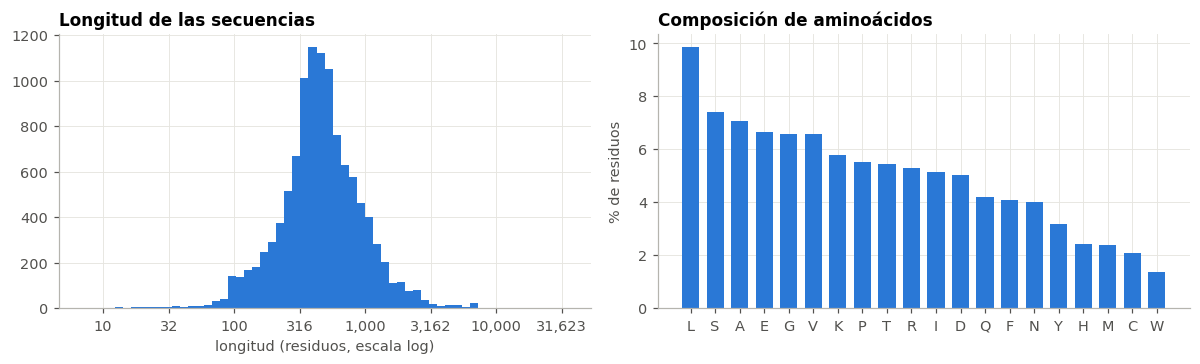

In [29]:
usadas = seqs[seqs["seq_id1"].isin(bd["seq_id1"].dropna().unique())].copy()
usadas["longitud"] = usadas["secuencia"].str.len()
print(f"Secuencias distintas (cadena 1): {len(usadas):,}")
display(usadas["longitud"].describe(percentiles=[.05, .5, .95]).round(0).to_frame("residuos").T)

con_minus = usadas["secuencia"].str.contains(r"[a-z]")
print(f"Secuencias con letras minúsculas: {con_minus.sum():,} ({pct(con_minus.sum(), len(usadas)):.1f}%) "
      f"— filas afectadas: {pct(bd['seq_id1'].isin(usadas.loc[con_minus, 'seq_id1']).sum(), n):.1f}%")
print("Ejemplo:", usadas.loc[con_minus, "secuencia"].iloc[0][:120] if con_minus.any() else "—")
otros = usadas["secuencia"].str.replace(r"[A-Za-z]", "", regex=True).str.len().gt(0)
print(f"Secuencias con caracteres no alfabéticos (espacios, dígitos, *): {otros.sum():,}")

comp = Counter()
for s in usadas["secuencia"]:
    comp.update(s.upper())
comp = pd.Series(comp).sort_values(ascending=False)
estandar = set("ACDEFGHIKLMNPQRSTVWY")
no_std = comp[[c for c in comp.index if c not in estandar]]
print("Símbolos (en mayúsculas) fuera de los 20 aminoácidos estándar [17]:", no_std.to_dict())

fig, axes = plt.subplots(1, 2, figsize=(11, 3.4))
axes[0].hist(np.log10(usadas["longitud"]), bins=60, color=AZUL)
axes[0].xaxis.set_major_formatter(mticker.FuncFormatter(lambda v, _: f"{10**v:,.0f}"))
axes[0].set_xlabel("longitud (residuos, escala log)"); axes[0].set_title("Longitud de las secuencias")
c20 = (100 * comp[comp.index.isin(estandar)] / comp.sum()).sort_values(ascending=False)
axes[1].bar(c20.index, c20.values, color=AZUL, width=0.7)
axes[1].set_ylabel("% de residuos"); axes[1].set_title("Composición de aminoácidos")
guardar(fig, "08_secuencias")

**Interpretación.**

- Las longitudes van de **péptidos o dominios cortos** (decenas de residuos) a proteínas de **miles** de residuos. La mediana corresponde a un dominio proteico típico de unos cientos.
- La composición sigue el patrón general de las proteínas, con Leu, Ala, Gly, Ser y Glu entre los más frecuentes.
- Los símbolos no estándar, como `X` (residuo desconocido o cualquiera) o `B`/`Z` (ambigüedad Asx/Glx) [17], son raros pero existen.
- **Hallazgo no documentado.** Unas pocas secuencias vienen en **minúsculas**, y un par contienen dígitos o guiones (restos de formato). Afectan a muy pocas filas. El código IUPAC usa mayúsculas [17] y la especificación de BindingDB no explica las minúsculas [2]. Así que **no conviene asignarles un significado** (p. ej. "región no observada") sin confirmarlo con BindingDB. En la práctica, cualquier comparación de secuencias debe normalizar a mayúsculas, y la composición de arriba se calculó así.

### Targets más estudiados

,UniProt,nombre,mediciones,ligandos
0,P00533,Epidermal growth factor receptor,31585,15650
1,P07949,Proto-oncogene tyrosine-protein kinase receptor Ret,27879,4726
2,P01116,GTPase KRas,27626,11353
3,Q06187,Tyrosine-protein kinase BTK,26196,12830
4,O60674,Tyrosine-protein kinase JAK2,25521,16705
5,O60885,Bromodomain-containing protein 4,24106,12756
6,P23458,Tyrosine-protein kinase JAK1,20123,13722
7,Q12809,Voltage-gated inwardly rectifying potassium channel KCNH2,18767,14298
8,P29597,Non-receptor tyrosine-protein kinase TYK2,18698,9200
9,P51449,Nuclear receptor ROR-gamma,18357,11152


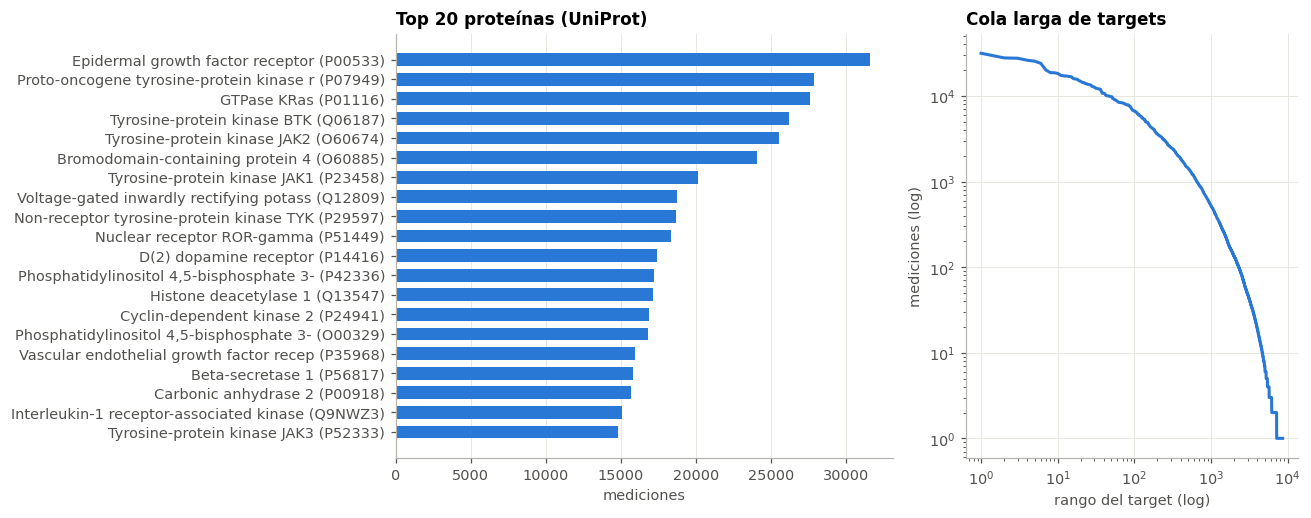

El 1% de proteínas más medidas concentra el 33.2% de las mediciones


In [30]:
t_code, t_uniq = pd.factorize(bd["uniprot1"])
ok_t = t_code >= 0
med_por_t = np.bincount(t_code[ok_t])
lig_por_t = np.bincount(pd.DataFrame({"t": t_code, "l": lig_code})[ok_t & valido].drop_duplicates()["t"], minlength=len(t_uniq))
nombre_t = pd.Series(bd["sp_name1"].astype(object).to_numpy(), index=t_code)[ok_t].groupby(level=0).first()
top_t = pd.DataFrame({"UniProt": t_uniq.astype(object), "nombre": nombre_t.reindex(range(len(t_uniq))).values,
                      "mediciones": med_por_t, "ligandos": lig_por_t}).nlargest(20, "mediciones")
display(top_t.reset_index(drop=True))

fig, axes = plt.subplots(1, 2, figsize=(12, 4.8), gridspec_kw={"width_ratios": [1.5, 1]})
tt = top_t.iloc[::-1]
axes[0].barh(tt["nombre"].fillna("(sin nombre)").str.slice(0, 40) + " (" + tt["UniProt"] + ")", tt["mediciones"], color=AZUL, height=0.65)
axes[0].grid(axis="y", visible=False); axes[0].set_xlabel("mediciones"); axes[0].set_title("Top 20 proteínas (UniProt)")
r = np.sort(med_por_t)[::-1]
axes[1].loglog(np.arange(1, len(r) + 1), r, color=AZUL, lw=2)
axes[1].set_xlabel("rango del target (log)"); axes[1].set_ylabel("mediciones (log)"); axes[1].set_title("Cola larga de targets")
guardar(fig, "08_top_targets")
top10 = np.sort(med_por_t)[::-1][:max(1, len(med_por_t) // 100)].sum()
H["% mediciones en el 1% de targets más medidos"] = f"{pct(top10, med_por_t.sum()):.1f}%"
print(f"El 1% de proteínas más medidas concentra el {pct(top10, med_por_t.sum()):.1f}% de las mediciones")

**Interpretación.** La atención está **muy concentrada**: el 1 % de las proteínas acumula alrededor de un tercio de las mediciones. El top está dominado por **cinasas** (EGFR, RET, BTK, JAK1/2, TYK2, PI3Kα) y por targets oncológicos recientes como **KRAS** y **BRD4**. También aparece **KCNH2 (hERG)**, un canal de potasio que se mide sistemáticamente como *anti-target* por riesgo de toxicidad cardiaca, no porque se quiera inhibir. Mientras tanto, miles de proteínas tienen solo un puñado de mediciones. Es un **sesgo de investigación**: refleja dónde ha invertido la industria, no la biología.

# <div style="border-left:4px solid #3D6FB0;padding:4px 0 6px 14px;margin:16px 0 6px 0;"><span style="color:#3D6FB0;font-size:21px;font-weight:700;">9. Pares ligando–target y variabilidad experimental</span></div>

Un mismo par (ligando, target) puede medirse **varias veces**: en distintos artículos, laboratorios o ensayos. La dispersión entre esas mediciones repetidas indica **cuánto ruido experimental** hay en los datos [11]. Se usan solo valores exactos (sin `>`/`<`) y se agrupa por (InChIKey, Target Name, tipo de medición).

,pares únicos,% pares con >1 medición,SD mediana entre repeticiones (p),% pares con rango > 1 log
tipo,,,,
Ki,383321,19.99,0.12,20.34
IC50,1287085,20.95,0.12,20.22
Kd,56671,24.16,0.17,29.35
EC50,157410,21.12,0.18,23.14


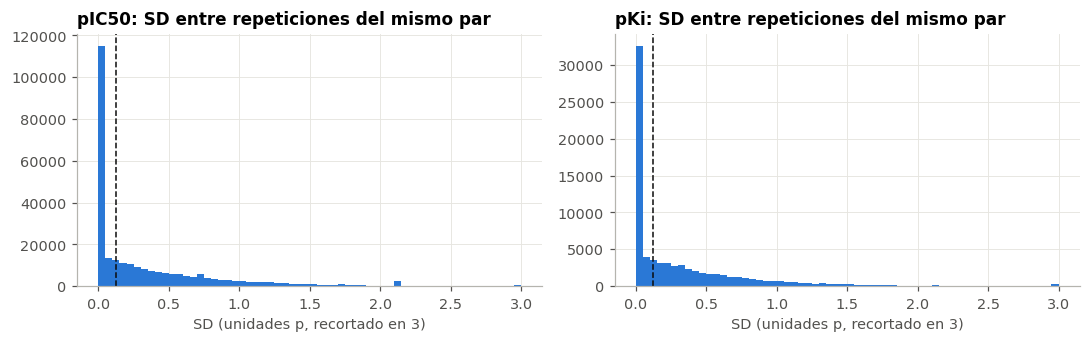

In [31]:
largo = []
for t in TIPOS:
    m = (bd[f"{t}_qual"].isna() & (bd[t] > 0)).to_numpy() & valido & (tcode >= 0)
    largo.append(pd.DataFrame({"tipo": t, "l": lig_code[m], "t": tcode[m], "p": 9 - np.log10(bd[t].to_numpy()[m])}))
largo = pd.concat(largo, ignore_index=True)
g = largo.groupby(["tipo", "l", "t"]).p.agg(n="size", sd="std", mn="min", mx="max", mediana="median")
g["rango"] = g["mx"] - g["mn"]

rep = g[g["n"] > 1]
resumen_rep = pd.DataFrame({
    "pares únicos": g.groupby("tipo").size(),
    "% pares con >1 medición": 100 * rep.groupby("tipo").size() / g.groupby("tipo").size(),
    "SD mediana entre repeticiones (p)": rep.groupby("tipo")["sd"].median(),
    "% pares con rango > 1 log": 100 * (rep["rango"] > 1).groupby("tipo").mean(),
}).loc[TIPOS]
display(resumen_rep.round(2))
H["SD mediana entre repeticiones (pIC50 / pKi)"] = (f"{resumen_rep.loc['IC50', 'SD mediana entre repeticiones (p)']:.2f} / "
                                                    f"{resumen_rep.loc['Ki', 'SD mediana entre repeticiones (p)']:.2f}")

fig, axes = plt.subplots(1, 2, figsize=(10, 3.2), sharey=False)
for ax, t in zip(axes, ["IC50", "Ki"]):
    v = rep.loc[t, "sd"].dropna()
    ax.hist(v.clip(upper=3), bins=60, color=AZUL)
    ax.axvline(v.median(), color="#0b0b0b", ls="--", lw=1)
    ax.set_title(f"p{t}: SD entre repeticiones del mismo par"); ax.set_xlabel("SD (unidades p, recortado en 3)")
guardar(fig, "09_variabilidad")

**Interpretación.** Medir el mismo par varias veces **no da el mismo número**. La SD mediana entre repeticiones es baja (≈ 0.1–0.2 unidades log), porque muchos pares repetidos son la **misma medición reportada dos veces**. Aun así, alrededor de uno de cada cinco pares repetidos difiere en **más de 10×** (rango > 1 log). Kalliokoski *et al.* reportaron una dispersión de IC50 públicos mayor que la de Ki [11], coherente con que IC50 depende de las condiciones del ensayo [5][6]. Esta variabilidad es una **propiedad de los datos** que cualquier análisis posterior debe tener presente.

### Ki frente a IC50 para el mismo par

Por Cheng–Prusoff, en inhibición competitiva **IC50 ≥ Ki**, es decir, pIC50 ≤ pKi [5]. ¿Se observa en los pares medidos con ambas?

Pares con Ki e IC50: 33,910 | r = 0.789 | mediana(pKi − pIC50) = +0.41 (factor ≈ 2.55×) | pKi > pIC50 en 75.5% de los pares


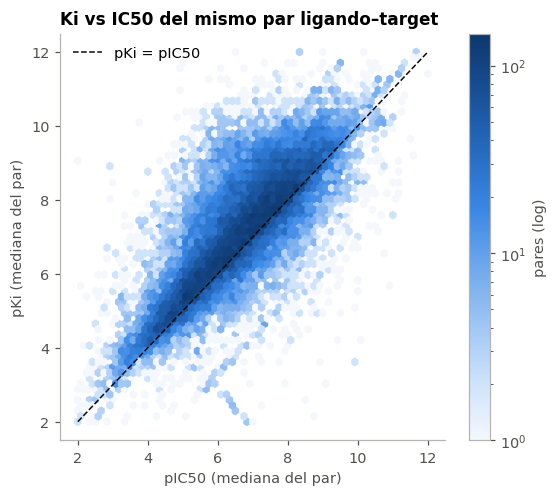

In [32]:
med = g["mediana"].unstack("tipo")
ambos = med[["Ki", "IC50"]].dropna()
dif = ambos["Ki"] - ambos["IC50"]
r = np.corrcoef(ambos["Ki"], ambos["IC50"])[0, 1]
print(f"Pares con Ki e IC50: {len(ambos):,} | r = {r:.3f} | mediana(pKi − pIC50) = {dif.median():+.2f} "
      f"(factor ≈ {10**dif.median():.2f}×) | pKi > pIC50 en {pct((dif > 0).sum(), len(dif)):.1f}% de los pares")

fig, ax = plt.subplots(figsize=(5.2, 4.6))
hb = ax.hexbin(ambos["IC50"], ambos["Ki"], gridsize=60, cmap=SEQ_CMAP, mincnt=1, bins="log", extent=(2, 12, 2, 12))
ax.plot([2, 12], [2, 12], color="#0b0b0b", lw=1, ls="--", label="pKi = pIC50")
ax.set_xlabel("pIC50 (mediana del par)"); ax.set_ylabel("pKi (mediana del par)"); ax.legend(loc="upper left")
ax.set_title("Ki vs IC50 del mismo par ligando–target"); ax.grid(False)
fig.colorbar(hb, ax=ax, label="pares (log)")
guardar(fig, "09_ki_vs_ic50")
H["Mediana pKi − pIC50 (mismo par)"] = f"{dif.median():+.2f}"

**Interpretación.** La correlación es clara pero con mucha dispersión, porque cada valor viene de ensayos distintos. La diferencia mediana positiva (pKi algo mayor que pIC50) es la **dirección esperada por Cheng–Prusoff** [5] y es del orden del factor ~2 que reportan Kalliokoski *et al.* [11]. Ki e IC50 **están relacionadas pero no son intercambiables**.

### Posibles registros duplicados

Se cuentan las filas idénticas en ligando, target, valores, condiciones, fuente y entrada. Pueden ser repeticiones legítimas (distintos ensayos dentro de un mismo artículo, que se distinguen en el archivo de ensayos [1]) o duplicación por importar la misma fuente por dos vías.

In [33]:
clave = ["inchikey", "target", "source", "entry_doi", "pH", "temp_C"] + [c for t in TIPOS for c in (t, f"{t}_qual")]
dup = bd.duplicated(subset=clave, keep="first")
print(f"Filas idénticas en {len(clave)} campos clave: {dup.sum():,} ({pct(dup.sum(), n):.2f}%)")
display(bd.loc[dup, "source"].value_counts().head(6).to_frame("filas duplicadas por fuente"))

Filas idénticas en 14 campos clave: 100,150 (3.09%)


,filas duplicadas por fuente
source,
US Patent,52024
ChEMBL,45131
PDSP Ki,1476
Curated from the literature by BindingDB,1020
PubChem,253
WIPO,153


# <div style="border-left:4px solid #3D6FB0;padding:4px 0 6px 14px;margin:16px 0 6px 0;"><span style="color:#3D6FB0;font-size:21px;font-weight:700;">10. Condiciones experimentales: pH y temperatura</span></div>

pH y temperatura son condiciones del ensayo [2] e influyen en la afinidad medida, sobre todo en IC50 [6].

,% con pH,% con temperatura
source,,
ChEMBL,0.3,0.0
US Patent,11.8,11.1
PubChem,3.8,5.6
Curated from the literature by BindingDB,44.4,43.9
PDSP Ki,0.0,0.0
WIPO,0.0,0.0
D3R,3.4,0.0
CSAR,43.6,43.6
"Taylor Research Group, UCSD",100.0,100.0


Formato de temperatura 'NN.NN C' válido: 100.00%
pH fuera de [0, 14]: 0 | temperatura fuera de [0, 100] °C: 791


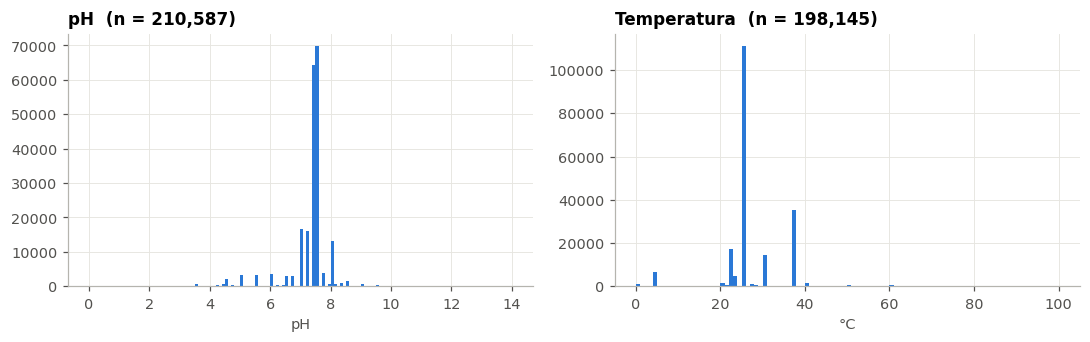

In [34]:
cond = pd.DataFrame({"% con pH": bd["pH"].notna(), "% con temperatura": bd["temp_C"].notna()}
                    ).groupby(bd["source"], observed=True).mean().mul(100).round(1)
display(cond.loc[src.index])
print(f"Formato de temperatura 'NN.NN C' válido: {pct(bd['temp_raw_ok'].sum(), bd['temp_raw_ok'].notna().sum()):.2f}%")
print(f"pH fuera de [0, 14]: {((bd['pH'] < 0) | (bd['pH'] > 14)).sum():,} | "
      f"temperatura fuera de [0, 100] °C: {((bd['temp_C'] < 0) | (bd['temp_C'] > 100)).sum():,}")

fig, axes = plt.subplots(1, 2, figsize=(10, 3.2))
axes[0].hist(bd["pH"].dropna().clip(0, 14), bins=np.arange(0, 14.1, 0.1), color=AZUL)
axes[0].set_xlabel("pH"); axes[0].set_title(f"pH  (n = {bd['pH'].notna().sum():,})")
axes[1].hist(bd["temp_C"].dropna().clip(0, 100), bins=np.arange(0, 100.5, 1), color=AZUL)
axes[1].set_xlabel("°C"); axes[1].set_title(f"Temperatura  (n = {bd['temp_C'].notna().sum():,})")
guardar(fig, "10_condiciones")
H["% filas con pH / temperatura"] = f"{pct(bd['pH'].notna().sum(), n):.1f}% / {pct(bd['temp_C'].notna().sum(), n):.1f}%"

### Temperaturas imposibles: rastro de conversiones de unidades

Hay temperaturas fuera de [0, 100] °C. Se prueba una hipótesis: que sean **25 °C o 37 °C con la conversión K ↔ °C (± 273.15) aplicada una o varias veces por error**.

In [35]:
fuera = bd.loc[(bd["temp_C"] < 0) | (bd["temp_C"] > 100), ["temp_C", "source"]]
filas = []
for base in (25.0, 37.0):
    k = (fuera["temp_C"] - base) / 273.15
    exacto = (k - k.round()).abs() < 1e-3
    filas.append({"temperatura base": f"{base:g} °C", "filas explicadas": int(exacto.sum()),
                  "veces que se sumó/restó 273.15": sorted(k[exacto].round().astype(int).unique().tolist())})
display(pd.DataFrame(filas))
print("Valores más comunes fuera de rango:", fuera["temp_C"].value_counts().head(8).to_dict())
display(fuera["source"].value_counts().head(4).to_frame("filas fuera de rango por fuente"))

,temperatura base,filas explicadas,veces que se sumó/restó 273.15
0,25 °C,297,"[-1, 1, 2, 3, 4, 5, 6]"
1,37 °C,16,[1]


Valores más comunes fuera de rango: {-80.0: 413, 1390.75: 72, 1663.9: 54, 571.3: 48, -248.15: 46, -70.0: 41, 1117.6: 36, 844.45: 36}


,filas fuera de rango por fuente
source,
US Patent,464
Curated from the literature by BindingDB,327
CSAR,0
D3R,0


**Interpretación.**

- Los valores como 571.30, 844.45, 1117.60… son exactamente **298.15 K + n × 273.15**, y −248.15 = 25 − 273.15. Es la huella de una **conversión de unidades aplicada repetidamente** (°C → K varias veces), no de temperaturas reales. Los valores de −80 °C o −70 °C probablemente reflejan la **temperatura de almacenamiento** de la muestra y no la del ensayo, aunque es una suposición. Son pocas filas, pero muestran que **incluso los campos numéricos "simples" necesitan validación**.
- Las condiciones se registran sobre todo en los datos **curados directamente** (BindingDB literatura, CSAR, depósitos de grupos) y parcialmente en las patentes. Las filas importadas de ChEMBL y PDSP prácticamente nunca las traen, como advierten Kalliokoski *et al.* para las bases públicas en general [11]. Donde existen, se concentran en el **pH fisiológico (~7.4)** y en **25 °C / 37 °C**, las temperaturas estándar de laboratorio y fisiológica.

# <div style="border-left:4px solid #3D6FB0;padding:4px 0 6px 14px;margin:16px 0 6px 0;"><span style="color:#3D6FB0;font-size:21px;font-weight:700;">11. Estructuras 3D (PDB)</span></div>

`Ligand HET ID in PDB` indica que el ligando existe como componente químico en el PDB [18]. `PDB ID(s) for Ligand-Target Complex` lista las **estructuras cristalográficas o de RMN del complejo**, con una proteína al ≥ 85 % de identidad [2].

In [36]:
tiene_pdb = bd["pdb_complex"].notna(); tiene_het = bd["het"].notna()
lig_con_pdb = pd.Series(tiene_pdb.to_numpy())[valido].groupby(lig_code[valido]).any()
lig_con_het = pd.Series(tiene_het.to_numpy())[valido].groupby(lig_code[valido]).any()
print(f"Mediciones con estructura 3D del complejo: {pct(tiene_pdb.sum(), n):.2f}% | ligandos únicos: {pct(lig_con_pdb.sum(), len(lig_con_pdb)):.2f}%")
print(f"Ligandos con código HET en el PDB: {pct(lig_con_het.sum(), len(lig_con_het)):.2f}%")
n_pdb = bd.loc[tiene_pdb, "pdb_complex"].astype(object).str.count(",") + 1
print(f"Entradas PDB por medición (cuando hay): mediana {n_pdb.median():.0f}, máx {n_pdb.max():,}")
ids_pdb = pd.Series(bd.loc[tiene_pdb, "pdb_complex"].astype(object).str.split(",").explode().str.strip().unique())
print(f"Entradas PDB distintas: {len(ids_pdb):,} | formato de 4 caracteres: {pct(ids_pdb.str.fullmatch(r'[0-9][A-Za-z0-9]{3}').sum(), len(ids_pdb)):.2f}%")
print("Top códigos HET:", bd["het"].value_counts().head(10).to_dict())
H["Ligandos con estructura 3D del complejo"] = f"{pct(lig_con_pdb.sum(), len(lig_con_pdb)):.2f}%"

Mediciones con estructura 3D del complejo: 3.50% | ligandos únicos: 0.77%
Ligandos con código HET en el PDB: 0.80%
Entradas PDB por medición (cuando hay): mediana 2, máx 799
Entradas PDB distintas: 51,839 | formato de 4 caracteres: 100.00%
Top códigos HET: {'AZM': 2588, 'STO': 2485, 'SHH': 2214, 'BAX': 1747, '1N1': 1240, 'AQ4': 1216, 'GMJ': 1210, 'IRE': 1183, '2K2': 1171, 'ZD6': 1015}


**Interpretación.** Solo una **fracción muy pequeña** de los ligandos tiene una estructura 3D experimental con su target. La enorme mayoría de BindingDB es información **2D** (SMILES) más **secuencia**, sin geometría del complejo. Los códigos HET más frecuentes corresponden a los **ligandos más medidos** de la sección 7.2, como `STO` (estaurosporina) y `AZM` (acetazolamida). Aparecen ya los **códigos de 5 caracteres** que el wwPDB emite desde 2023 [28]; los de 1–2 caracteres son iones o moléculas pequeñas históricas [18].

# <div style="border-left:4px solid #3D6FB0;padding:4px 0 6px 14px;margin:16px 0 6px 0;"><span style="color:#3D6FB0;font-size:21px;font-weight:700;">12. Resumen de hallazgos</span></div>

La tabla se genera a partir de las variables calculadas arriba, sin números escritos a mano.

In [37]:
display(pd.Series(H, name="valor").to_frame())

,valor
Mediciones (filas),"3,243,660 (oficial 3,241,782)"
Ligandos distintos (InChIKey),"1,354,629"
Targets distintos (Target Name / UniProt),"8,940 / 8,594"
Tipo de afinidad más frecuente,IC50 (68.5% de filas)
% IC50 censurados (> o <),21.2%
Mediana pIC50 / pKi (valores exactos),6.76 / 7.18
Fuente principal,ChEMBL (51.1%)
Ligandos con un solo target,66.0%
Ligandos con estereocentros,34.2%
Ligandos con DrugBank ID,0.19%


### Lo que hay que tener presente sobre estos datos

1. **Una fila es una medición, no un par único.** El mismo par ligando–target aparece varias veces, con valores que pueden diferir en más de un orden de magnitud (sección 9).
2. **Las afinidades no son homogéneas.** Ki y Kd son constantes de equilibrio, IC50 depende del ensayo y EC50 es funcional [5][6][7]. Además, el tipo de medición está confundido con la fuente (sección 6).
3. **Hay datos censurados** (`>`/`<`): una parte importante de los IC50 solo dice "inactivo hasta X" (sección 5.2).
4. **"Target" tiene varias granularidades**: nombre con construcción, accession UniProt o complejo multicadena (sección 8).
5. **"Compuesto" también**: SMILES (no único), InChIKey (molécula exacta) o esqueleto (sin estereo) (sección 7).
6. **Cola larga y sesgo de investigación**: pocos targets y pocos ligandos concentran la mayoría de las mediciones (secciones 7.2 y 8.6).
7. **Faltan metadatos de ensayo**: pH y temperatura casi solo existen en los datos curados por BindingDB, y la descripción del ensayo vive en un archivo aparte [1].

# <div style="border-left:4px solid #3D6FB0;padding:4px 0 6px 14px;margin:16px 0 6px 0;"><span style="color:#3D6FB0;font-size:21px;font-weight:700;">Referencias</span></div>

**BindingDB**
1. BindingDB. *Download* (release 202611, actualizado 2026-10-31). https://www.bindingdb.org/rwd/bind/chemsearch/marvin/Download.jsp
2. BindingDB. *Tab-Separated Value (TSV) Files from BindingDB* (especificación de columnas, 7 jul 2025). https://www.bindingdb.org/rwd/bind/chemsearch/marvin/BindingDB-TSV-Format.pdf
3. BindingDB. *About / Info* (fuentes, técnicas, licencias). https://www.bindingdb.org/rwd/bind/info.jsp
4. Liu T., Hwang L., Burley S.K., Nitsche C.I., Southan C., Walters W.P., Gilson M.K. *BindingDB in 2024: a FAIR knowledgebase of protein–small molecule binding data.* Nucleic Acids Research 53(D1):D1633–D1644 (2025). https://doi.org/10.1093/nar/gkae1075 · https://www.ncbi.nlm.nih.gov/pmc/articles/PMC11701568/

**Afinidad, cinética y comparabilidad**

5. Cheng Y., Prusoff W.H. *Relationship between the inhibition constant (Ki) and the concentration of inhibitor which causes 50 per cent inhibition (I50) of an enzymatic reaction.* Biochemical Pharmacology 22(23):3099–3108 (1973). https://doi.org/10.1016/0006-2952(73)90196-2
6. *IC50* (incluye la relación de Cheng–Prusoff y sus limitaciones). Wikipedia. https://en.wikipedia.org/wiki/IC50
7. Tocris Bioscience. *Pharmacological Glossary* (definiciones de Ki, Kd, IC50, EC50). https://www.tocris.com/resources/pharmacological-glossary
8. GraphPad. *Key concepts: law of mass action* (Kd = koff/kon; unidades). https://www.graphpad.com/guides/prism/latest/curve-fitting/reg_key_concepts_law_of_mass_actio.htm
9. BMG Labtech. *Receptor–ligand kinetics for research and drug discovery* (tiempo de residencia = 1/koff). https://www.bmglabtech.com/en/blog/receptor-ligand-kinetics-for-research-and-drug-discovery/
10. ChEMBL. *Assay and Activity Questions — pChEMBL* (−log10 molar; solo relación "="). https://chembl.gitbook.io/chembl-interface-documentation/frequently-asked-questions/chembl-data-questions
11. Kalliokoski T., Kramer C., Vulpetti A., Gedeck P. *Comparability of Mixed IC50 Data – A Statistical Analysis.* PLoS ONE 8(4):e61007 (2013). https://doi.org/10.1371/journal.pone.0061007

**Representación de moléculas**

12. Daylight Chemical Information Systems. *Daylight Theory Manual, cap. 3: SMILES — A Simplified Chemical Language.* https://www.daylight.com/dayhtml/doc/theory/theory.smiles.html · tutorial: https://www.daylight.com/dayhtml_tutorials/languages/smiles/index.html
13. InChI Trust. *InChI Technical Manual* (capas del InChI y estructura del InChIKey). https://www.inchi-trust.org/download/104/InChI_TechMan.pdf
14. *International Chemical Identifier (InChI / InChIKey).* Wikipedia. https://en.wikipedia.org/wiki/International_Chemical_Identifier

**Proteínas**

15. UniProt. *Entry name* (formato X_Y, códigos de especie, estabilidad de accessions). https://www.uniprot.org/help/entry_name
16. UniProt / Expasy. *UniProtKB user manual* (Swiss-Prot revisado vs TrEMBL no revisado; accessions de 6 y 10 caracteres). https://web.expasy.org/docs/userman.html · https://www.uniprot.org/help/accession_numbers
17. IUPAC–IUBMB. *Nomenclature and Symbolism for Amino Acids and Peptides* (código de una letra). https://iupac.qmul.ac.uk/AminoAcid/A2021.html
18. wwPDB. *Chemical Component Dictionary* (códigos HET de ≤3 caracteres). https://www.wwpdb.org/data/ccd

**Identificadores externos del ligando**

19. PubChem — tipos de registro (Substance/SID, Compound/CID, BioAssay/AID). https://rebelford.github.io/DataChem2025Book/content/modules/02-Introduction/02-1-PubChemDataTypes.html · https://chem.libretexts.org/Courses/Fordham_University/Chem1102%3A_Drug_Discovery_-_From_the_Laboratory_to_the_Clinic/12%3A_Chemical_and_Biological_Databases/12.02%3A_Data_Organization_in_PubChem_as_a_Data_Aggregator
20. ChEMBL. *ChEMBL Identifiers.* https://chembl.github.io/chembl-identifiers
21. *ChEBI — Chemical Entities of Biological Interest.* Wikipedia. https://en.wikipedia.org/wiki/ChEBI
22. DrugBank. *Field descriptions — DrugBank ID (DB + 5 dígitos).* https://dev.drugbank.com/guides/fields/drugs
23. KEGG. *Drug identifiers (D number)* y *KEGG WebLinks (C number)*. https://www.kegg.jp/kegg/medicus/drugcode.html · https://www.kegg.jp/kegg/docs/weblinks.html
24. Irwin J.J. *et al.* *ZINC20 — A Free Ultralarge-Scale Chemical Database for Ligand Discovery.* J. Chem. Inf. Model. 60:6065–6073 (2020). https://zinc20.docking.org
25. IUPHAR/BPS Guide to PHARMACOLOGY. *Help.* https://www.guidetopharmacology.org/helpPage.jsp

**Otras fuentes de datos**

26. *Ki Database (PDSP, NIMH Psychoactive Drug Screening Program).* Wikipedia. https://en.wikipedia.org/wiki/Ki_Database
27. CSAR (Community Structure–Activity Resource). *CSAR Benchmark Exercise of 2010.* J. Chem. Inf. Model. (2011). https://pmc.ncbi.nlm.nih.gov/articles/PMC3180202
28. wwPDB / PDBj. *Issuing 5-character CCD IDs* y *PDB entries with extended CCD or PDB IDs will be distributed in PDBx/mmCIF format only.* https://pdbj.org/news/Issuing_5-character_CCDID · https://pdbj.org/news/ExtensionCCDCodes
29. Gaieb Z. *et al.* *D3R Grand Challenge 3: blind prediction of protein–ligand poses and affinity rankings.* J. Comput.-Aided Mol. Des. (2019). https://pmc.ncbi.nlm.nih.gov/articles/PMC6472484